# Proyecto N°1 · Elementos de Máquinas · Grupo 1
**Diseño de uniones en un sistema de transmisión de potencia** — notebook de cálculo (v2, marco de referencia de la pauta 2026)

## Marco de referencia (pauta 2026)
| Elemento | Definición |
|---|---|
| Ejes | X,Y,Z mano derecha. **Z = eje del árbol, positivo hacia el motor (hacia la izquierda en la Fig. 1)**. Y vertical hacia arriba. X horizontal transversal, positivo **hacia el observador** (opuesto a la polea G). |
| Coordenada axial | `s` = distancia desde el apoyo 1 hacia F (como en la pauta: 0,30 · 1,05 · 1,45 · 1,65 m). Por tanto **z = −s**. Los gráficos usan `s`. |
| Giro | Motor A y piñón B giran en **+z**; engrane C y eje giran en **−z** (pauta, §DCL del eje). |
| `R_*` (C, D, F) | Fuerza **del eje sobre** engrane/polea. Sobre el eje actúa **−R_*** (acción-reacción), como en las ecuaciones de la pauta. |
| `R1`, `R2` | Reacciones de los soportes **sobre** el eje. Apoyo 1: solo x,y. Apoyo 2: x,y,z. |
| Pares | `T_*` en las tablas = módulo. Componente z del par **sobre el eje**: C = −T_C, D = +T_D, F = +T_F. |
| Diagramas | V y M positivos por plano con la convención usual de viga (suma de cargas a la izquierda, `s` creciente). **T(s) = Σ pares z sobre el eje a la izquierda de la sección** (regla de la mano derecha sobre +z). |

## Cambio respecto al notebook anterior (V1)
Rotación de 180° del triedro alrededor de Y: **x → −x, z → −z, y sin cambio**. Las magnitudes físicas no cambian.
| Magnitud | Efecto |
|---|---|
| `R_x`, `V_x`, `M(plano XZ)` | cambian de signo |
| `R_y`, `V_y`, `M(plano YZ)` | sin cambio |
| `T(s)` | cambia de signo: **empieza negativo (−T_C) y vuelve a 0** |
| `M_res`, `|T|`, esfuerzos, factores de seguridad | idénticos |

**Estructura (títulos de la pauta):** 0 Datos · 1 Potencias · 2 DCL y determinación de fuerzas · 3 Diagramas de momento flector y torsor · 4 Diseño de elementos mecánicos · 5 Verificación del eje (fatiga y fluencia) · 6 Discusión y conclusiones.
Todo número editable está en `DATOS`, `UNIONES` y `FORZAR` (celda 0).

> ✍️ **REDACTAR · Introducción y Metodología**  _(borrar este recuadro al terminar)_
>
> - **Contexto** (1–2 párrafos + estado del arte con ≥ 2 referencias en APA/IEEE): importancia de las transmisiones por engranes y correas ⟦RELLENAR⟧; brecha o pregunta: diseño de uniones eje–cubo bajo flexión y torsión cíclicas ⟦RELLENAR⟧.
> - **Objetivo general:** ⟦RELLENAR: diseñar y verificar las uniones C (chaveta), D (interferencia), F (pasador) y planchas (apernada) con N_fatiga = `N_f`⟧.
> - **Objetivos específicos:** los 6 de la pauta (DCL del eje · diagramas de flector y torsor · uniones · plano del eje · plano de planchas · N a fluencia).
> - **Metodología:** análisis estático del conjunto; eje simplemente apoyado (el soporte no transmite momento); la potencia del motor alterna entre 0 y 10 HP (arranque–parada) ⟦RELLENAR: cómo se traduce en componentes medias y alternantes, ver §5⟧; N = `N_f`.
> - Figuras de esta sección: Fig. 1 sistema ⟦cambiar por el dibujo propio⟧ · Fig. 2 DCL del eje · Fig. 3 DCL engrane C · Fig. 4 DCL polea D · Fig. 5 unión por interferencia ⟦dibujar⟧.

In [3]:
# =====================================================================
# 0. DATOS DE ENTRADA  —  ÚNICO lugar donde se editan números
# =====================================================================
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle, Circle
from IPython.display import display

DATOS = {
    'motor':    {'P_HP': 10, 'rpm': 120},                                  # Tabla 1, grupo 1
    'engranes': {'phi_deg': 20, 'd_B': 0.060, 'd_C': 0.120},               # [m] diámetros primitivos
    'polea_D':  {'d': 0.150, 'd_par': 0.050, 'C': 0.500, 'frac_P': 0.50},  # d_par = polea E ; C = dist. centros [m] ; frac_P = fracción de P_eje que consume D (SUPUESTO: no está en el enunciado)
    'polea_F':  {'d': 0.180, 'd_par': 0.080, 'C': 0.600},                  # d_par = polea G ; F consume 1 − frac_P(D)
    'correa':   {'mu': 0.3,
                 'criterio_beta': 'pequena'},   # 'pequena': β = π − 2θ (arco de la polea chica, gobierna el deslizamiento, conservador)
                                                # 'grande' : β = π + 2θ (fórmula escrita en la pauta, arco de la polea grande)
    'eje':      {'d': 0.040, 'L': 1.70},                                   # [m] Ø nominal (enunciado) ; largo total (SUPUESTO)
    'pos':      {'Ap1': 0.0, 'C': 0.30, 'D': 1.05, 'Ap2': 1.45, 'F': 1.65},  # [m] distancia s desde el apoyo 1
    'N_f':      1.6,                                                       # factor de seguridad a la FATIGA (Tabla 1, grupo 1)
    'mat_eje':  {'nombre': 'SAE 1045', 'Sr': 640.0, 'S0': 340.0, 'E': 195000.0},   # [MPa]
}

# Supuestos de diseño de las uniones (cada uno debe justificarse en el informe)
UNIONES = {
    'chaveta': {'b': 12, 'h': 8, 'L': 70,        # [mm] 12×8 = valor normalizado para Ø40 (ANSI/DIN 6885, igual que el informe de referencia); L ≥ L_min
                'S0': 340.0,                     # [MPa] material de la chaveta ⟦RELLENAR: p.ej. ASTM 1020 → 300⟧ (V1 asumía el mismo acero del eje)
                'nombre': '⟦RELLENAR material⟧'},
    'interf':  {'mu': 0.1, 't_cubo': 60.0,       # [-] roce ; [mm] ancho del cubo de D (SUPUESTO, confirmado con el profesor)
                'Ra': 1.6},                      # [µm] rugosidad eje y cubo (SUPUESTO) para el alisado de Falk
    'pasador': {'D_N': 80.0, 'd_p': 22.0},       # [mm] Ø del cubo de F ; Ø del pasador (prueba)
}

# Sobrescritura manual de resultados del DCL (vacío = usar el cálculo). Ej.: FORZAR = {'R_Dy': -18000.0}
FORZAR = {}

# ---- alias usados por el resto del notebook (no editar) ----
mo, ge, pD, pF, co = DATOS['motor'], DATOS['engranes'], DATOS['polea_D'], DATOS['polea_F'], DATOS['correa']
ej, pos, mat, N_f = DATOS['eje'], DATOS['pos'], DATOS['mat_eje'], DATOS['N_f']
d_eje, d_d = ej['d'], pD['d']                                   # [m]
Sr_eje, S0_eje, E_eje = mat['Sr'], mat['S0'], mat['E']          # [MPa]
phi = np.radians(ge['phi_deg'])
v = lambda nombre, calculo: FORZAR.get(nombre, calculo)         # aplica FORZAR si existe

## 1. Determinación de las potencias transmitidas

In [4]:
# =====================================================================
# 1. DETERMINACIÓN DE LAS POTENCIAS TRANSMITIDAS
# =====================================================================
P_motor = mo['P_HP']*746                                  # [W]
w_B = mo['rpm']*2*np.pi/60                                # [rad/s] módulo (B gira en +z)
w_C = w_B*ge['d_B']/ge['d_C']                             # [rad/s] módulo (C y eje giran en −z)
omega = {'B': +w_B, 'C': -w_C, 'eje': -w_C}               # [rad/s] componente según +z
P_eje = P_motor                                           # transmisión sin pérdidas (informe: P_eje = P_D + P_F)
P_D = pD['frac_P']*P_eje;  P_F = P_eje - P_D              # [W]
M_B = P_motor/w_B                                         # [N·m] par del motor sobre B
M_C = P_eje/w_C                                           # [N·m] módulo del par que C entrega al eje
M_D, M_F = P_D/w_C, P_F/w_C                               # [N·m] módulo de los pares que D y F toman del eje

TABLA_POTENCIAS = pd.DataFrame([
    ('Motor A / piñón B', 'P_motor',  P_motor, 'W',     'P = 10 HP · 746'),
    ('Piñón B',           'ω_B',      omega['B'], 'rad/s', 'gira en +z'),
    ('Engrane C y eje',   'ω_C',      omega['C'], 'rad/s', 'gira en −z'),
    ('Piñón B',           'M_B',      M_B, 'N·m',   'P/ω_B'),
    ('Engrane C',         'T_C',      M_C, 'N·m',   'P_eje/|ω_C|'),
    ('Polea D',           'P_D',      P_D, 'W',     f"{pD['frac_P']*100:.0f} % de P_eje (supuesto)"),
    ('Polea F',           'P_F',      P_F, 'W',     f"{(1-pD['frac_P'])*100:.0f} % de P_eje"),
    ('Polea D',           'T_D',      M_D, 'N·m',   'P_D/|ω_eje|'),
    ('Polea F',           'T_F',      M_F, 'N·m',   'P_F/|ω_eje|'),
], columns=['Elemento', 'Símbolo', 'Valor', 'Unidad', 'Nota']).round(3)
display(TABLA_POTENCIAS)
assert abs(M_C - M_D - M_F) < 1e-9, 'T_C = T_D + T_F'

,Elemento,Símbolo,Valor,Unidad,Nota
0,Motor A / piñón B,P_motor,7460.000,W,P = 10 HP · 746
1,Piñón B,ω_B,12.566,rad/s,gira en +z
2,Engrane C y eje,ω_C,-6.283,rad/s,gira en −z
3,Piñón B,M_B,593.648,N·m,P/ω_B
4,Engrane C,T_C,1187.296,N·m,P_eje/|ω_C|
5,Polea D,P_D,3730.000,W,50 % de P_eje (supuesto)
6,Polea F,P_F,3730.000,W,50 % de P_eje
7,Polea D,T_D,593.648,N·m,P_D/|ω_eje|
8,Polea F,T_F,593.648,N·m,P_F/|ω_eje|


> ✍️ **REDACTAR · §1 Determinación de las potencias transmitidas**  _(borrar este recuadro al terminar)_
>
> - Ecuación P_eje = P_D + P_F, con la hipótesis de transmisión sin pérdidas.
> - Reparto de potencia entre D y F: **no está en el enunciado**; se supuso ⟦50 % / 50 %: justificar o consultar⟧ (`DATOS["polea_D"]["frac_P"]`). El informe de referencia usó 40 % / 60 %.
> - Valores a citar: P_motor, ω_B, ω_C, M_B, T_C, T_D, T_F (tabla `TABLA_POTENCIAS`).

## 2. Diagramas de cuerpo libre y determinación de fuerzas

In [5]:
# =====================================================================
# 2. DCL Y DETERMINACIÓN DE FUERZAS   (marco nuevo: x hacia el observador, y arriba, z hacia el motor)
# =====================================================================
# --- 2.1 Engrane C: el diente de B empuja a C en (+r_C, 0) con F_BC a 20° ---
F_t  = M_B/(ge['d_B']/2)                       # [N] componente tangencial
F_r  = F_t*np.tan(phi)                         # [N] componente radial
F_BC = F_t/np.cos(phi)                         # [N] fuerza total sobre el diente
#   fuerza de B sobre C = (−F_r, −F_t)  ->  el eje reacciona sobre C con R_C = (+F_r, +F_t)
R_Cx, R_Cy = v('R_Cx', +F_r), v('R_Cy', +F_t)  # [N] eje sobre C
T_C = v('T_C', F_t*ge['d_C']/2)                # [N·m] = F_BC·cos20°·d_C/2 (módulo). El eje aplica +z sobre C

# --- 2.2 Poleas D y F: capstan T1 = T2·e^(μβ) ; T = (T1−T2)·d/2 ---
def correa(pul, par):
    th   = np.arcsin((pul['d'] - pul['d_par'])/2/pul['C'])         # [rad] semiángulo de la correa
    beta = np.pi - 2*th if co['criterio_beta'] == 'pequena' else np.pi + 2*th
    k    = np.exp(co['mu']*beta)
    T2   = par/((k - 1)*pul['d']/2); T1 = k*T2                     # [N] lado flojo / tenso
    return th, beta, T1, T2
th_D, beta_D, T1_D, T2_D = correa(pD, M_D)
th_F, beta_F, T1_F, T2_F = correa(pF, M_F)
# D: ramales verticales hacia E; el lado tenso queda en +x.  F: ramales horizontales hacia G (−x); lado tenso arriba.
R_Dx, R_Dy = v('R_Dx', +(T1_D - T2_D)*np.sin(th_D)), v('R_Dy', -(T1_D + T2_D)*np.cos(th_D))   # [N] eje sobre D  (ΣF pauta)
R_Fx, R_Fy = v('R_Fx', +(T1_F + T2_F)*np.cos(th_F)), v('R_Fy', +(T1_F - T2_F)*np.sin(th_F))   # [N] eje sobre F
T_D, T_F = v('T_D', M_D), v('T_F', M_F)        # [N·m] módulos

# --- 2.3 Eje: equilibrio global tomando momentos en el apoyo 1 (ecuaciones de la pauta, z = −s) ---
sC, sD, s2, sF = pos['C'], pos['D'], pos['Ap2'], pos['F']
marcas = {'Ap.1': pos['Ap1'], 'C': sC, 'D': sD, 'Ap.2': s2, 'F': sF}      # para rotular gráficos
R2y = (sC*R_Cy + sD*R_Dy + sF*R_Fy)/s2         # 1,45·R2y = 0,3·RCy + 1,05·RDy + 1,65·RFy
R2x = (sC*R_Cx + sD*R_Dx + sF*R_Fx)/s2         # 1,45·R2x = 0,3·RCx + 1,05·RDx + 1,65·RFx
R1y = R_Cy + R_Dy + R_Fy - R2y                 # R1y + R2y = RCy + RDy + RFy
R1x = R_Cx + R_Dx + R_Fx - R2x
R2z = 0.0                                      # ΣFz = 0 (engranes rectos, correas en el plano XY)

# --- 2.4 Estructura de datos del DCL (valores editables arriba; aquí solo se ordenan) ---
DCL = {
  'engrane_C': {'F_BC': F_BC, 'F_t': F_t, 'F_r': F_r, 'phi_deg': ge['phi_deg'], 'R_Cx': R_Cx, 'R_Cy': R_Cy, 'T_C': T_C},
  'polea_D':   {'F1': T1_D, 'F2': T2_D, 'theta_rad': th_D, 'beta_rad': beta_D, 'R_Dx': R_Dx, 'R_Dy': R_Dy, 'T_D': T_D},
  'polea_F':   {'F1': T1_F, 'F2': T2_F, 'theta_rad': th_F, 'beta_rad': beta_F, 'R_Fx': R_Fx, 'R_Fy': R_Fy, 'T_F': T_F},
  'eje':       {'R1x': R1x, 'R1y': R1y, 'R2x': R2x, 'R2y': R2y, 'R2z': R2z,
                'T_eje_z': {'C': -T_C, 'D': +T_D, 'F': +T_F}},           # pares z SOBRE el eje [N·m]
}
filas = []
for el, dic in DCL.items():
    for sim, val in dic.items():
        if isinstance(val, dict): continue
        u = 'N·m' if sim.startswith('T_') else ('°' if sim == 'phi_deg' else ('rad' if sim.endswith('rad') else 'N'))
        filas.append((el, sim, val, u))
TABLA_DCL = pd.DataFrame(filas, columns=['Elemento', 'Símbolo', 'Valor', 'Unidad'])
TABLA_DCL['Valor'] = TABLA_DCL['Valor'].astype(float).round(3)
display(TABLA_DCL)

# --- 2.5 Chequeos independientes ---
# (a) equilibrio vectorial en el marco nuevo con r = (0, 0, −s):  ΣF = 0 ,  Σ(r×F) + ΣT = 0
cargas = [(pos['Ap1'], np.array([R1x, R1y, 0.0])), (sC, -np.array([R_Cx, R_Cy, 0.0])), (sD, -np.array([R_Dx, R_Dy, 0.0])),
          (s2, np.array([R2x, R2y, R2z])), (sF, -np.array([R_Fx, R_Fy, 0.0]))]
pares = [(sC, -T_C), (sD, +T_D), (sF, +T_F)]
sumF = sum(f for _, f in cargas)
sumM = sum(np.cross([0, 0, -si], f) for si, f in cargas) + np.array([0, 0, sum(t for _, t in pares)])
print(f'ΣF = {np.round(sumF, 9)} N | ΣM(apoyo 1) = {np.round(sumM, 9)} N·m   (deben ser 0)')
# (b) ecuaciones de la pauta, una a una (residuos)
print('Residuos pauta: ΣFx %.1e | ΣFy %.1e | ΣMx %.1e | ΣMy %.1e | ΣMz %.1e' % (
    R1x + R2x - (R_Cx + R_Dx + R_Fx), R1y + R2y - (R_Cy + R_Dy + R_Fy),
    -sC*R_Cy - sD*R_Dy + s2*R2y - sF*R_Fy, sC*R_Cx + sD*R_Dx - s2*R2x + sF*R_Fx, T_C - T_D - T_F))
# (c) coherencia de las poleas con la pauta y balance de potencia
print('Poleas: (T1−T2)·r_D = %.2f = T_D | (T1−T2)·r_F = %.2f = T_F N·m' % ((T1_D - T2_D)*pD['d']/2, (T1_F - T2_F)*pF['d']/2))
print('Potencia: T_C·|ω_C| = %.0f W = P_motor = %.0f W' % (T_C*w_C, P_motor))

,Elemento,Símbolo,Valor,Unidad
0,engrane_C,F_BC,21058.231,N
1,engrane_C,F_t,19788.265,N
2,engrane_C,F_r,7202.339,N
3,engrane_C,phi_deg,20.000,°
4,engrane_C,R_Cx,7202.339,N
5,engrane_C,R_Cy,19788.265,N
6,engrane_C,T_C,1187.296,N·m
7,polea_D,F1,13502.693,N
8,polea_D,F2,5587.388,N
9,polea_D,theta_rad,0.100,rad


ΣF = [ 0. -0.  0.] N | ΣM(apoyo 1) = [-0.  0.  0.] N·m   (deben ser 0)
Residuos pauta: ΣFx 0.0e+00 | ΣFy -4.5e-13 | ΣMx -6.8e-13 | ΣMy 0.0e+00 | ΣMz 0.0e+00
Poleas: (T1−T2)·r_D = 593.65 = T_D | (T1−T2)·r_F = 593.65 = T_F N·m
Potencia: T_C·|ω_C| = 7460 W = P_motor = 7460 W


In [6]:
# ===== Utilidades de dibujo para los DCL (solo gráficos; los números vienen de DCL / TABLA_DCL) =====
def _fl(a, x, y, dx, dy, txt='', c='tab:blue', ha='left', va='bottom', lw=2):
    """Flecha con COLA en (x,y) y vector (dx,dy)."""
    a.annotate('', xy=(x + dx, y + dy), xytext=(x, y), arrowprops=dict(arrowstyle='-|>', color=c, lw=lw, mutation_scale=14))
    if txt: a.text(x + dx, y + dy, txt, color=c, ha=ha, va=va, fontsize=9)
def _par(a, r, ccw, txt, c='tab:red', yt=1.15, ypos=None):
    """Arco de par alrededor del centro; ccw=True: antihorario visto desde +z (z sale de la hoja)."""
    t = np.radians(np.linspace(30, 150, 60) if ccw else np.linspace(150, 30, 60))
    a.plot(r*np.cos(t), r*np.sin(t), c=c, lw=2)
    a.annotate('', xy=(r*np.cos(t[-1]), r*np.sin(t[-1])), xytext=(r*np.cos(t[-4]), r*np.sin(t[-4])),
               arrowprops=dict(arrowstyle='-|>', color=c, lw=2, mutation_scale=14))
    a.text(0.02, 0.98, txt, color=c, ha='left', va='top', fontsize=9, transform=a.transAxes)   # rótulo del par en la esquina
def _vista(a, R, tit):
    a.set_aspect('equal'); a.set_xlim(-R, R); a.set_ylim(-R, R); a.axis('off'); a.set_title(tit, fontsize=10)
    ox, oy, l = -R*.82, -R*.8, R*.3                                   # triedro (vista desde +z) abajo a la izquierda
    a.annotate('', xy=(ox + l, oy), xytext=(ox, oy), arrowprops=dict(arrowstyle='-|>', lw=1.5)); a.text(ox + l*1.1, oy, 'x', va='center')
    a.annotate('', xy=(ox, oy + l), xytext=(ox, oy), arrowprops=dict(arrowstyle='-|>', lw=1.5)); a.text(ox, oy + l*1.1, 'y', ha='center')
    a.plot(ox, oy, 'ko', ms=8, mfc='w'); a.plot(ox, oy, 'k.', ms=3); a.text(ox - l*.1, oy - l*.35, 'z (sale)', fontsize=8, ha='left', va='top')

# ---- Figuras · DCL de las poleas D y F (vista desde +z; x → derecha, y ↑) ----
def dcl_polea(nombre, pul, dic, th, Rx, Ry, tipo):
    r = pul['d']/2; k = 0.8*r/dic['F1']; T1, T2 = dic['F1'], dic['F2']
    if tipo == 'D':   # ramales verticales hacia E; lado tenso en +x
        P1, u1, P2, u2 = r*np.array([np.cos(th), np.sin(th)]), np.array([-np.sin(th), np.cos(th)]), r*np.array([-np.cos(th), np.sin(th)]), np.array([np.sin(th), np.cos(th)])
        ref = 'hacia E'
    else:             # ramales horizontales hacia G (−x); lado tenso arriba
        P1, u1, P2, u2 = r*np.array([-np.sin(th), np.cos(th)]), np.array([-np.cos(th), -np.sin(th)]), r*np.array([-np.sin(th), -np.cos(th)]), np.array([-np.cos(th), np.sin(th)])
        ref = 'hacia G'
    fig, a = plt.subplots(figsize=(6.4, 5.8)); R = 2.2*r
    a.add_patch(Circle((0, 0), r, fc='#eef7ee', ec='k')); a.add_patch(Circle((0, 0), r*.27, fc='w', ec='k')); _vista(a, R, f'DCL polea {nombre}')
    _fl(a, *P1, *(T1*k*u1), f'F1 = {T1:.0f} N (tenso)', 'tab:green', ha='left' if tipo == 'D' else 'right', va='bottom'); _fl(a, *P2, *(T2*k*u2), f'F2 = {T2:.0f} N (flojo)', 'tab:green', ha='right')
    _fl(a, 0, 0, Rx*k, Ry*k, f'R_{nombre} = ({Rx:.0f}; {Ry:.0f}) N', 'tab:blue', va='top')
    _par(a, r*.5, False, f"T_{nombre} = {dic['T_'+nombre]:.1f} N·m (−z sobre la polea)", yt=1.2, ypos=(None if tipo == 'D' else -r*.8))
    a.text(0, -R*.97, f"θ = {np.degrees(th):.2f}°  ·  β = {np.degrees(dic['beta_rad']):.1f}°  ·  ramales {ref}", ha='center', fontsize=8); plt.show()

### 2.1 DCL del engrane C

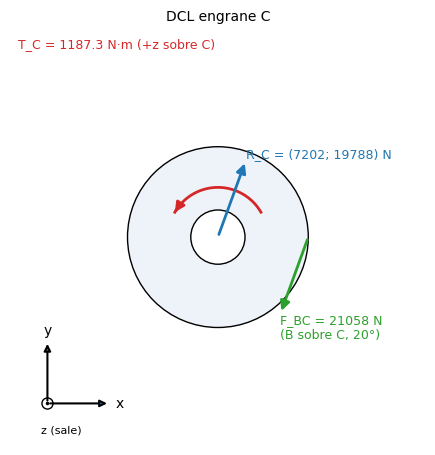

In [7]:
# ---- Figura · DCL del engrane C (vista desde +z; x → derecha, y ↑) ----
d = DCL['engrane_C']; r = ge['d_C']/2; k = 0.9*r/d['F_BC']
fig, a = plt.subplots(figsize=(6.4, 5.4)); R = 2.3*r
a.add_patch(Circle((0, 0), r, fc='#eef3fa', ec='k')); a.add_patch(Circle((0, 0), r*.3, fc='w', ec='k')); _vista(a, R, 'DCL engrane C')
_fl(a, r, 0, -d['F_r']*k, -d['F_t']*k, f"F_BC = {d['F_BC']:.0f} N\n(B sobre C, {d['phi_deg']:.0f}°)", 'tab:green', ha='left', va='top')
_fl(a, 0, 0, d['R_Cx']*k, d['R_Cy']*k, f"R_C = ({d['R_Cx']:.0f}; {d['R_Cy']:.0f}) N", 'tab:blue')
_par(a, r*.55, True, f"T_C = {d['T_C']:.1f} N·m (+z sobre C)", ypos=-r*.75)
plt.show()

### 2.2 DCL de la polea D

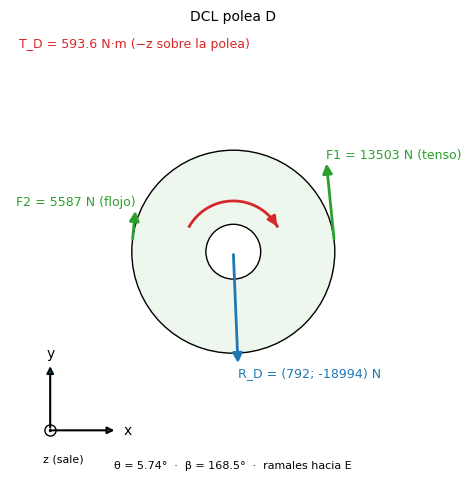

In [8]:
dcl_polea('D', pD, DCL['polea_D'], th_D, R_Dx, R_Dy, 'D')

### 2.3 DCL de la polea F

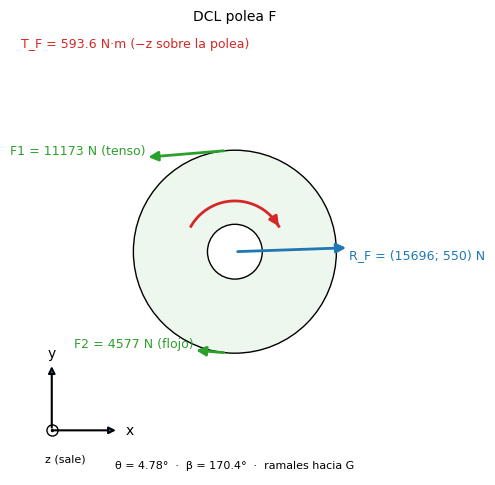

In [9]:
dcl_polea('F', pF, DCL['polea_F'], th_F, R_Fx, R_Fy, 'F')

### 2.4 DCL del eje

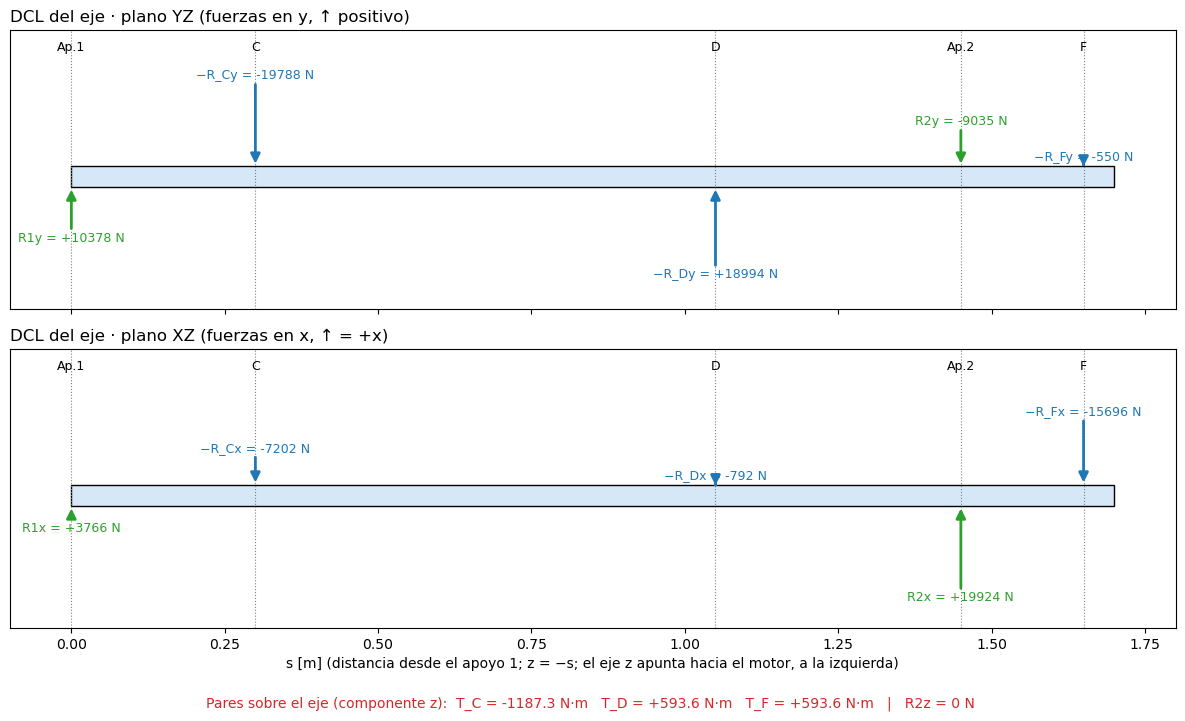

In [10]:
# ---- Figura · DCL del eje: FUERZAS SOBRE EL EJE (= −R de cada elemento) y reacciones ----
Lx = ej['L']; lista = [(n, si, f) for (si, f), n in zip(cargas, ['R1', 'C', 'D', 'R2', 'F'])]
Fmax = max(abs(f[c]) for _, _, f in lista for c in (0, 1)); h = 0.05
nom = {'R1': ('R1', 'tab:green'), 'R2': ('R2', 'tab:green'), 'C': ('−R_C', 'tab:blue'), 'D': ('−R_D', 'tab:blue'), 'F': ('−R_F', 'tab:blue')}
fig, ax = plt.subplots(2, 1, figsize=(12, 7.2), sharex=True)
for a, c, plano, tr in ((ax[0], 1, 'plano YZ (fuerzas en y, ↑ positivo)', 'y'), (ax[1], 0, 'plano XZ (fuerzas en x, ↑ = +x)', 'x')):
    a.add_patch(Rectangle((0, -h), Lx, 2*h, fc='#d6e8f8', ec='k'))
    for n, si, f in lista:
        val = f[c]; L = 0.42*abs(val)/Fmax; sg = np.sign(val); lab, col = nom[n]
        if abs(val) < 1e-6: continue
        y0 = -sg*(h + L); _fl(a, si, y0, 0, sg*L, '', col)
        a.text(si, y0, f'{lab}{tr} = {val:+.0f} N', color=col, ha='center', va='top' if sg > 0 else 'bottom', fontsize=9)
    for nm_, si in marcas.items(): a.axvline(si, ls=':', c='gray', lw=.8); a.text(si, 0.62, nm_, ha='center', fontsize=9)
    a.set_ylim(-.65, .72); a.set_yticks([]); a.set_title(f'DCL del eje · {plano}', loc='left')
ax[1].set_xlim(-.1, Lx + .1); ax[1].set_xlabel('s [m] (distancia desde el apoyo 1; z = −s; el eje z apunta hacia el motor, a la izquierda)')
tx = '   '.join(f'T_{k_} = {t:+.1f} N·m' for k_, t in DCL['eje']['T_eje_z'].items())
fig.text(.5, .01, f'Pares sobre el eje (componente z):  {tx}   |   R2z = {R2z:.0f} N', ha='center', fontsize=10, color='tab:red')
plt.tight_layout(rect=(0, .04, 1, 1)); plt.show()

> ✍️ **REDACTAR · §2 Diagramas de cuerpo libre y determinación de fuerzas**  _(borrar este recuadro al terminar)_
>
> - **DCL del eje:** marco de referencia (tabla de la portada), sentido de giro (motor +z, C y eje −z), qué transmite cada soporte, fuerzas R_* "en sentido contrario a las de los soportes". Copiar ecuaciones de equilibrio (las seis de la pauta, verificadas en la celda 2.5).
> - **Engrane C:** ecuaciones de F_BC y T_C. ⚠ La pauta escribe F_BC = P/(ω·φ_B/2) —que es la componente **tangencial**— y luego T_C = F_BC·cos20°·φ_C/2; así T_C queda 6 % bajo (1115,7 N·m) y no cierra el balance de potencia. Aquí F_BC = F_t/cos φ (fuerza total) y T_C = F_t·φ_C/2 = 1187,3 N·m. ⟦confirmar criterio con el profesor⟧
> - **Polea D y F:** ángulo de contacto β y razón F1/F2 = e^(μβ). La pauta usa β = π + 2·asin(…) (arco de la polea **grande**); el cálculo por defecto usa β = π − 2·asin(…) (polea **chica**, la que desliza primero, más conservador). Elegir uno en `DATOS["correa"]["criterio_beta"]` y ⟦justificar⟧. Efecto: ver tabla de sensibilidad en la entrega.
> - Figuras de esta sección: Fig. DCL engrane C · DCL polea D · DCL polea F · DCL eje. Cada una debe citarse en el texto.
> - `TABLA_DCL` contiene todos los valores numéricos del DCL para copiarlos a una tabla del informe.

## 3. Diagramas de momento flector y torsor del eje

In [11]:
# =====================================================================
# 3. DIAGRAMAS DE MOMENTO FLECTOR Y TORSOR  (cálculo; los gráficos van en celdas separadas)
# =====================================================================
s = np.linspace(0, ej['L'], 3401)                                   # [m] distancia desde el apoyo 1 (z = −s)
def suma_izq(comp):   # Σ de cargas puntuales a la izquierda de cada sección (cortante)
    return sum(f[comp]*(s > si) for si, f in cargas)
def mom_izq(comp):    # Σ F·(s − s_i): momento flector del plano (+ = convexo hacia abajo, convención de viga)
    return sum(f[comp]*np.clip(s - si, 0, None) for si, f in cargas)
DIAG = {'s': s,
        'V_y': suma_izq(1), 'M_YZ': mom_izq(1),                    # plano YZ (cargas en y)  == momento alrededor de x
        'V_x': suma_izq(0), 'M_XZ': mom_izq(0)}                    # plano XZ (cargas en x)
DIAG['M_res'] = np.hypot(DIAG['M_YZ'], DIAG['M_XZ'])               # [N·m]
DIAG['T']     = sum(t*(s >= si) for si, t in pares)                # [N·m] torsor: Σ pares z a la izquierda
# chequeos: todo vuelve a 0 al final
print('Cierre: V_x, V_y, M_YZ, M_XZ, T al final = %.1e, %.1e, %.1e, %.1e, %.1e' % tuple(DIAG[k][-1] for k in ('V_x', 'V_y', 'M_YZ', 'M_XZ', 'T')))
i = np.argmax(DIAG['M_res'])
print(f"M_res máx = {DIAG['M_res'][i]:.0f} N·m en s = {s[i]:.2f} m | T: " +
      ' → '.join(f'{t:+.1f}' for t in [0, -T_C, -T_C + T_D, -T_C + T_D + T_F]) + ' N·m')

# Tabla de valores en las secciones principales (para el informe)
def en(si, lado=0): return int(np.argmin(abs(DIAG['s'] - (si + lado*1e-3))))   # índice de la sección s_i ± 1 mm
filas = []
for nom, si in marcas.items():
    ia, ib = en(si, -1), en(si, +1)
    filas.append((nom, si, DIAG['M_YZ'][ib], DIAG['M_XZ'][ib], DIAG['M_res'][ib], DIAG['T'][ia], DIAG['T'][ib]))
TABLA_SECCIONES = pd.DataFrame(filas, columns=['Sección', 's [m]', 'M_YZ [N·m]', 'M_XZ [N·m]', 'M_res [N·m]', 'T(s⁻) [N·m]', 'T(s⁺) [N·m]']).round({'s [m]': 2, 'M_YZ [N·m]': 1, 'M_XZ [N·m]': 1, 'M_res [N·m]': 1, 'T(s⁻) [N·m]': 1, 'T(s⁺) [N·m]': 1})
display(TABLA_SECCIONES)

def _marcas(a, etiquetas=True):
    for nom, si in marcas.items():
        a.axvline(si, ls=':', c='gray', lw=.9)
        if etiquetas: a.text(si, 1.02, nom, ha='center', va='bottom', fontsize=8, transform=a.get_xaxis_transform())
def _graf(a, y, yl, tit, c='tab:blue'):
    a.plot(DIAG['s'], y, c=c, lw=2); a.fill_between(DIAG['s'], y, alpha=.2, color=c); a.axhline(0, c='k', lw=.8)
    a.set_ylabel(yl); a.set_title(tit, pad=18); a.grid(True, ls=':'); _marcas(a)

Cierre: V_x, V_y, M_YZ, M_XZ, T al final = 0.0e+00, -4.5e-13, 1.3e-12, 8.0e-13, 0.0e+00
M_res máx = 4201 N·m en s = 1.05 m | T: +0.0 → -1187.3 → -593.6 → +0.0 N·m


,Sección,s [m],M_YZ [N·m],M_XZ [N·m],M_res [N·m],T(s⁻) [N·m],T(s⁺) [N·m]
0,Ap.1,0.00,10.4,3.8,11.0,0.0,0.0
1,C,0.30,3104.1,1126.2,3302.1,0.0,-1187.3
2,D,1.05,-3934.2,-1452.1,4193.6,-1187.3,-593.6
3,Ap.2,1.45,-109.4,-3123.5,3125.4,-593.6,-593.6
4,F,1.65,-0.0,0.0,0.0,-593.6,0.0


In [12]:
# =====================================================================
# ESTILO DE LOS DIAGRAMAS  ·  cambia SOLO esta celda y vuelve a ejecutar las figuras
# =====================================================================
ESTILO = {
    "figsize":   (11, 4),        # [pulgadas] ancho, alto de cada diagrama
    "familia":   "Arial",           # tipo de letra: "Arial", "Calibri", "Times New Roman", "DejaVu Sans"... (si no existe en tu PC usa DejaVu Sans)
    "fuente":    12,                # tamaño de números de los ejes, rótulos A1, C, D... y valores
    "fuente_ejes": 12,              # tamaño del texto de los ejes
    "linea":     "black",           # color de la curva
    "grosor":    1.3,               # grosor de la curva
    "relleno":   "0.85",            # gris del relleno: "0" negro ... "1" blanco ; None = sin relleno
    "marcas":    True,              # líneas verticales con rótulo en apoyos, C, D y F
    "marcas_estilo": (0, (1, 3)),   # tipo de línea de las marcas: punteada fina
    "valores":   True,              # escribir valores (en cada tramo o en cada punto)
    "decimales": 0,                 # decimales de los valores escritos
    "marco":     "abierto",         # "abierto" (sin borde arriba/derecha) | "completo"
    "grilla":    False,
    "My_mano_derecha": False,       # M_y: False = convención de viga (igual que las tablas) | True = signo de la regla de la mano derecha (opuesto)
    "M_hacia_abajo": False,         # True: momento flector dibujado hacia abajo (convención de estructuras)
    "dpi":       300,               # resolución al guardar con guardar="nombre.png"
}
ROTULOS = {"Ap.1": r"$A_1$", "C": r"$C$", "D": r"$D$", "Ap.2": r"$A_2$", "F": r"$F$"}   # texto sobre cada marca
EJE_X = "Distancia en el eje [m]"
EJE_Y = {"V_y":   "$V_y$ [N]",      "M_YZ": "$M_x$ [N·m]",    # plano YZ: el momento gira alrededor de x
         "V_x":   "$V_x$ [N]",      "M_XZ": "$M_y$ [N·m]",    # plano XZ: el momento gira alrededor de y
         "M_res": "$M_{res}$ [N·m]", "T":   "$T$ [N·m]"}
TIPO = {"V_y": "escalon", "V_x": "escalon", "T": "escalon",          # escalon: valor constante por tramo
        "M_YZ": "puntos", "M_XZ": "puntos", "M_res": "puntos"}        # puntos: valor en cada marca

def diagrama(clave, guardar=None):
    """Dibuja DIAG[clave] con el ESTILO de arriba. clave: V_y, M_YZ, V_x, M_XZ, M_res, T.  guardar='nombre.png' o '.pdf' lo guarda."""
    e = ESTILO; x, y = DIAG["s"], DIAG[clave]
    if clave == "M_XZ" and e["My_mano_derecha"]: y = -y
    puestos = {"Ap.1": pos["Ap1"], "C": pos["C"], "D": pos["D"], "Ap.2": pos["Ap2"], "F": pos["F"]}
    rc = {"font.family": [e["familia"], "DejaVu Sans"], "font.size": e["fuente"], "axes.labelsize": e["fuente_ejes"],
          "mathtext.default": "regular", "axes.formatter.use_mathtext": False}   # mathtext "regular": los subíndices usan la misma letra
    with plt.rc_context(rc):
        fig, ax = plt.subplots(figsize=e["figsize"])
        if e["relleno"] is not None: ax.fill_between(x, y, color=e["relleno"], lw=0)
        ax.plot(x, y, color=e["linea"], lw=e["grosor"])
        ax.axhline(0, color="black", lw=0.8)
        if e["marcas"]:
            for nom, si in puestos.items():
                ax.axvline(si, ls=e["marcas_estilo"], color="0.35", lw=0.8)
                ax.text(si, 1.0, ROTULOS[nom], transform=ax.get_xaxis_transform(), ha="center", va="bottom", fontsize=e["fuente"] + 1)
        if e["valores"]:
            umbral = 1e-3*np.abs(y).max(); pts = []
            if TIPO[clave] == "escalon":
                lim = sorted(set(puestos.values()) | {x[-1]}); tr = []              # tramos entre marcas: [inicio, fin, valor]
                for a0, b0 in zip(lim[:-1], lim[1:]):
                    v = y[np.argmin(abs(x - (a0 + b0)/2))]
                    if tr and abs(v - tr[-1][2]) <= umbral: tr[-1][1] = b0           # tramos vecinos con el mismo valor se unen
                    else: tr.append([a0, b0, v])
                pts = [((a0 + b0)/2, v, False) for a0, b0, v in tr if abs(v) > umbral]
            else:
                for si in puestos.values():
                    v = y[np.argmin(abs(x - si))]
                    if abs(v) > umbral: pts.append((si, v, True))
            for xp, v, punto in pts:
                if punto: ax.plot(xp, v, "o", color=e["linea"], ms=3)
                ax.annotate(f"{v:.{e['decimales']}f}".replace("-", "−"), (xp, v), textcoords="offset points", xytext=(0, 5 if v >= 0 else -13),
                            ha="center", fontsize=e["fuente"] - 1)
        lo, hi = min(y.min(), 0), max(y.max(), 0); pad = 0.2*(hi - lo)
        ax.set_ylim(lo - pad, hi + pad); ax.set_xlim(0, x[-1])
        if e["M_hacia_abajo"] and clave.startswith("M"): ax.invert_yaxis()
        ax.set_xlabel(EJE_X); ax.set_ylabel(EJE_Y[clave]); (ax.grid(True, ls=":", lw=0.5) if e["grilla"] else None)
        if e["marco"] == "abierto": ax.spines["top"].set_visible(False); ax.spines["right"].set_visible(False)
        fig.tight_layout()
        if guardar: fig.savefig(guardar, dpi=e["dpi"], bbox_inches="tight")
        plt.show()

### 3.1 Cortante · plano YZ

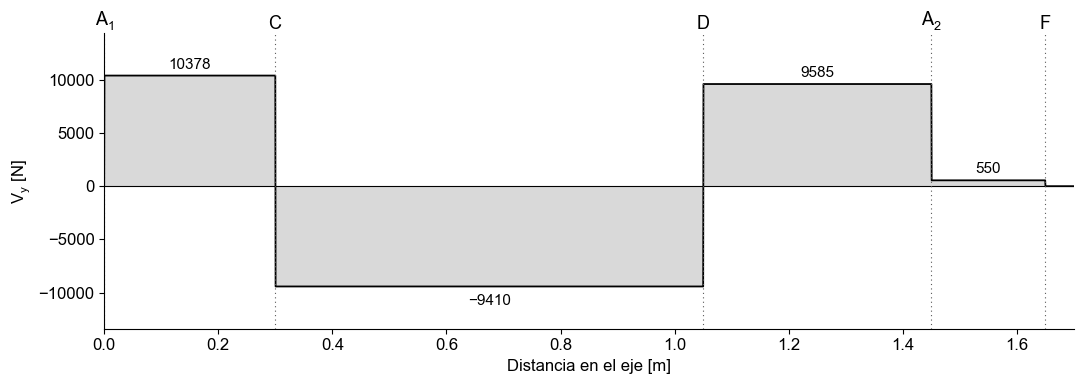

In [13]:
diagrama("V_y")

### 3.2 Momento flector · plano YZ

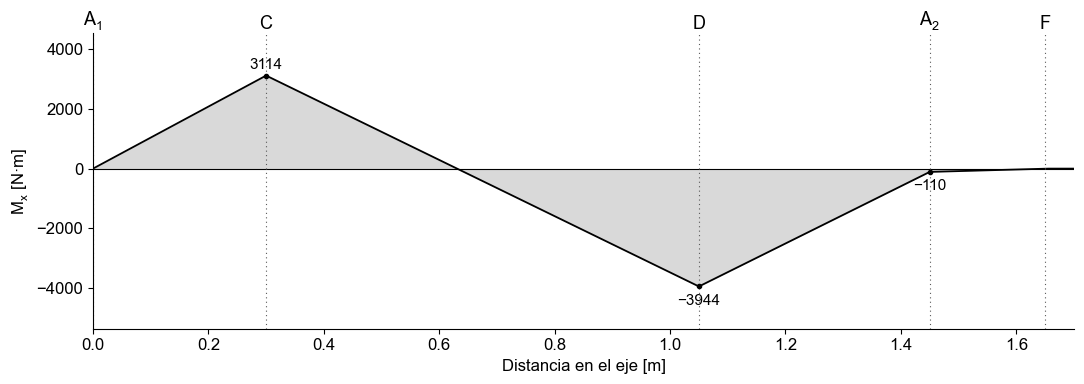

In [14]:
diagrama("M_YZ")

### 3.3 Cortante · plano XZ

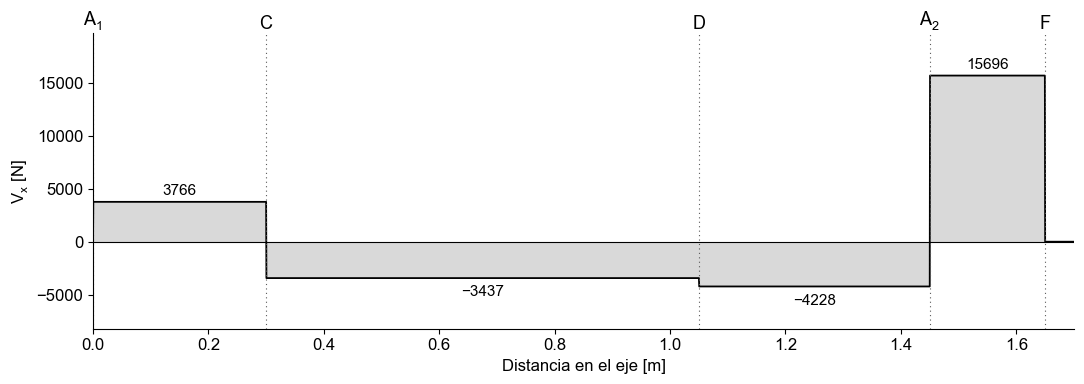

In [15]:
diagrama("V_x")

### 3.4 Momento flector · plano XZ

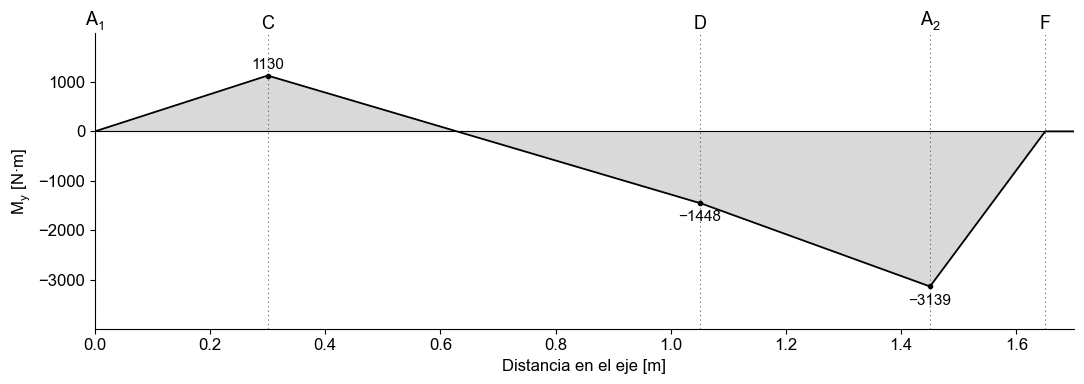

In [16]:
diagrama("M_XZ")

### 3.5 Momento flector resultante

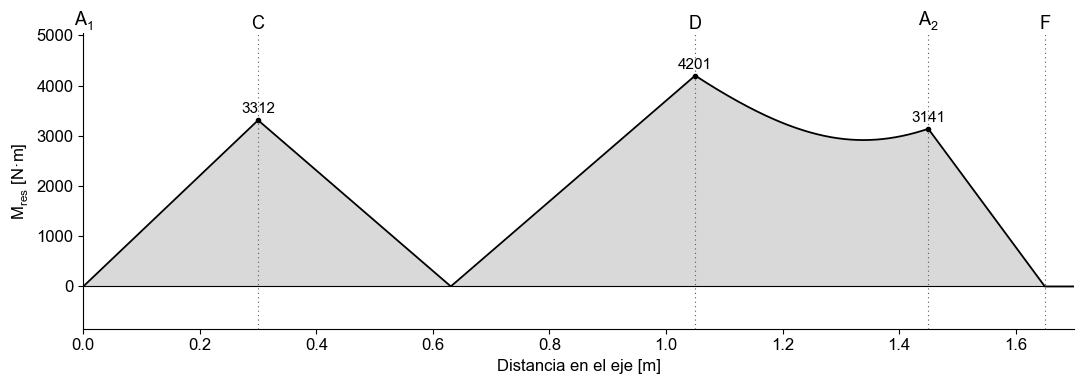

In [17]:
diagrama("M_res")

### 3.6 Momento torsor

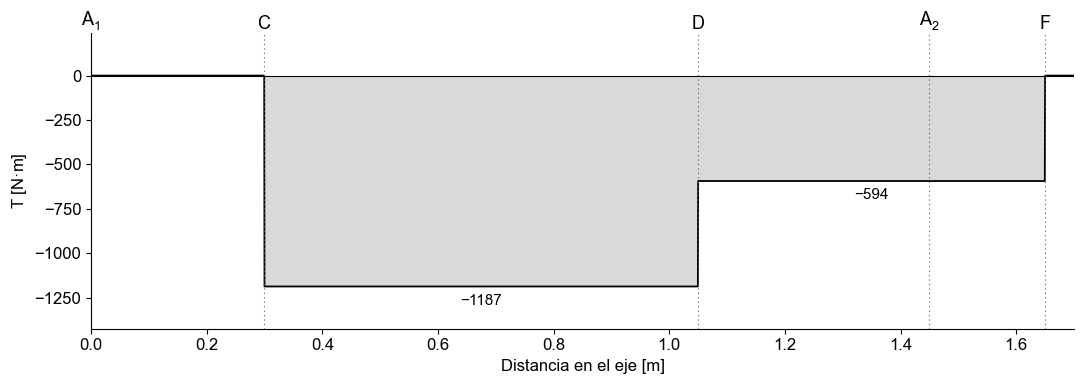

In [18]:
diagrama("T")

> ✍️ **REDACTAR · §3 Diagramas de momento flector y torsor**  _(borrar este recuadro al terminar)_
>
> - Convención de signos (copiar de la portada) y cambio de eje respecto del año anterior: V_x, M_XZ y T cambian de signo; V_y, M_YZ y M_res no.
> - Flector: valores en C, D, Ap.2 y F (`TABLA_SECCIONES`); sección crítica a flexión: ⟦D, s = 1,05 m, M_res = 4201 N·m⟧.
> - Torsor: T(s) = 0 → −T_C (entre C y D) → −T_C + T_D (entre D y F) → 0 después de F. Explicar que el signo negativo es consecuencia del eje z hacia el motor y que para el diseño se usa |T|; torsor máximo ⟦1187 N·m entre C y D⟧.
> - Verificación de cierre: M y T vuelven a 0 (mostrado en la celda de cálculo).
> - Figuras: Fig. flector YZ · Fig. flector XZ · Fig. flector resultante · Fig. torsor.

## 4. Diseño de elementos mecánicos
_(los planos de detalle van como anexo)_

### Propiedades de materiales

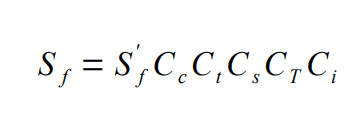

In [19]:
# =====================================================================
# PROPIEDADES DEL EJE (SAE 1045) Y LÍMITE DE FATIGA CORREGIDO  (EM1 diap. 10–19)
# =====================================================================
Sf_prima_eje = 0.5*Sr_eje if Sr_eje <= 1400 else 700.0     # [MPa] límite de fatiga de probeta, vida infinita
FAT = {'C_c': 1.0,    # carga combinada (diap. 14)
       'C_T': 1.0,    # T ≤ 100 °C (diap. 18)
       'C_i': 1.0,    # confiabilidad 50 %. Otras: 0,9→0,897 · 0,95→0,868 · 0,99→0,814   ⟦DECIDIR y justificar⟧
       'K_ff': 1.0,   # concentrador de fatiga en flexión   ⟦PENDIENTE: Kt→Kf en C (chavetero), D (interferencia), F (agujero del pasador)⟧
       'K_ft': 1.0}   # concentrador de fatiga en torsión   ⟦PENDIENTE⟧
def Sf_eje_fn(d_m):
    """Límite de fatiga corregido del eje [MPa] para un diámetro d_m [m]."""
    C_t = 0.879*(d_m*1000/25.4)**-0.107                  # tamaño, 0,11" < d ≤ 2" (diap. 15)
    C_s = 4.51*Sr_eje**-0.265                            # superficie, mecanizado (diap. 17)
    return Sf_prima_eje*FAT['C_c']*C_t*C_s*FAT['C_T']*FAT['C_i'], C_t, C_s
Sf_eje, C_t, C_s = Sf_eje_fn(d_eje)
print(f"S_r = {Sr_eje:.0f} | S_0 = {S0_eje:.0f} | S_f' = {Sf_prima_eje:.0f} | C_t = {C_t:.3f} | C_s = {C_s:.3f} | S_f = {Sf_eje:.1f} MPa")

S_r = 640 | S_0 = 340 | S_f' = 320 | C_t = 0.837 | C_s = 0.814 | S_f = 218.1 MPa


### 4.1 Diseño de chaveta en engrane C

Se asume que: $M_t=T=\dfrac{D}{2}F$, con $D$ del eje. Se elegirá chaveta prismática.

Corte: $\ \tau = \dfrac{F}{bL} \le \tau_{adm} = \dfrac{(S_0)_s}{N}\,,\quad (S_0)_s=\dfrac{S_0}{\sqrt3}$

Aplastamiento (compresión): $\ \sigma = \dfrac{2F}{Lh} \le \sigma_{adm} = \dfrac{S_0}{N}$ *(corregido: aquí va $S_0$, no $(S_0)_s$)*

Largo mínimo: $\ L_{min}=\max\!\left(\dfrac{F}{b\,\tau_{adm}},\ \dfrac{2F}{h\,\sigma_{adm}}\right)$

| Variable | Definición | Unidad |
|---|---|---|
| $M_t$ | Torque en C ($=M_C\cdot 1000$) | $[N\cdot mm]$ |
| $D$ | Diámetro del eje | $[mm]$ |
| $F$ | Fuerza en la chaveta | $[N]$ |
| $b,\ h,\ L$ | Ancho, alto y largo de la chaveta | $[mm]$ |
| $\tau,\ \sigma$ | Esfuerzos de corte y aplastamiento | $[MPa]=[N/mm^2]$ |
| $S_0,\ N$ | Fluencia del material / factor de seguridad | $[MPa]$ / $[-]$ |

F = 59365 N | tau = 70.7 MPa (adm 122.7) -> Resiste | sigma = 212.0 MPa (adm 212.5) -> Resiste
L_min = 69.8 mm para N = 1.6  (L usado = 70 mm)


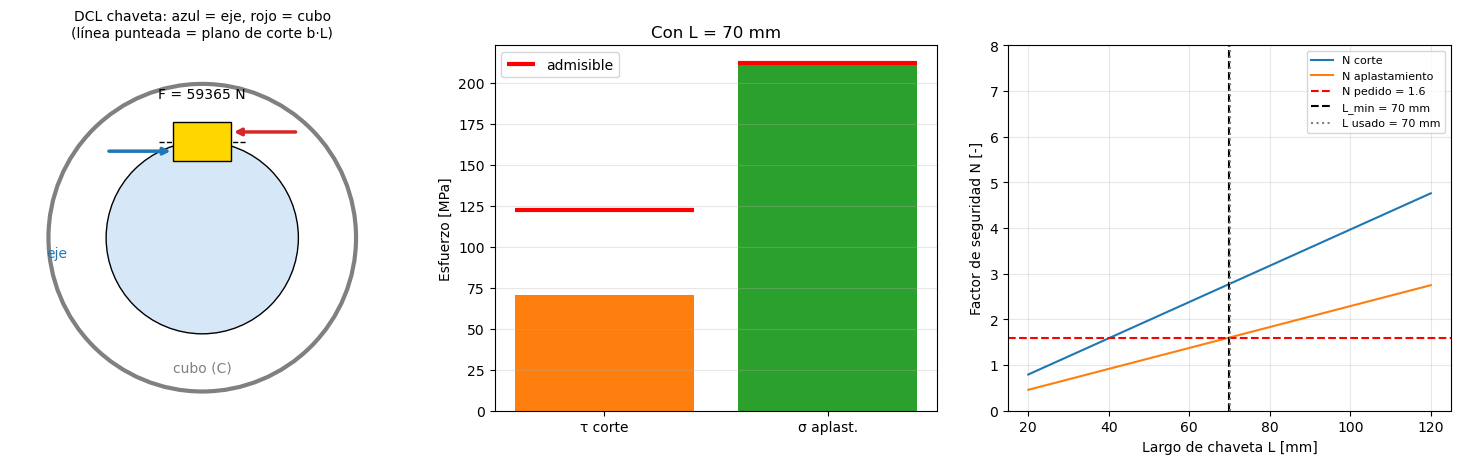

In [20]:
# ===== CHAVETA C–eje | unidades: N, mm, MPa =====
from matplotlib.patches import Rectangle, Circle
d_mm = d_eje*1000                        # [mm]   (d_eje está en m)
b_ch, h_ch, L_ch = (UNIONES['chaveta'][k_] for k_ in ('b', 'h', 'L'))   # [mm] ver UNIONES (celda 0)
S0_ch = UNIONES['chaveta']['S0']                                        # [MPa] material de la chaveta
T_Cmm  = M_C*1000                          # [N·mm] (M_C está en N·m)
F_ch = T_Cmm/(d_mm/2)                      # [N]    M_t = (D/2)·F
tau, sig = F_ch/(b_ch*L_ch), 2*F_ch/(L_ch*h_ch)                   # [MPa]
tau_adm, sig_adm = S0_ch/np.sqrt(3)/N_f, S0_ch/N_f              # [MPa]
L_min = max(F_ch/(b_ch*tau_adm), 2*F_ch/(h_ch*sig_adm))           # [mm]
ok = lambda x, xa: 'Resiste' if x <= xa else 'NO resiste'
print(f'F = {F_ch:.0f} N | tau = {tau:.1f} MPa (adm {tau_adm:.1f}) -> {ok(tau, tau_adm)} | sigma = {sig:.1f} MPa (adm {sig_adm:.1f}) -> {ok(sig, sig_adm)}')
print(f'L_min = {L_min:.1f} mm para N = {N_f}  (L usado = {L_ch} mm)')

fig, ax = plt.subplots(1, 3, figsize=(15, 4.6))
a0 = ax[0]; R = d_mm/2                                            # (a) DCL de la chaveta (sección transversal)
a0.add_patch(Circle((0,0), R, fc='#d6e8f8', ec='k')); a0.add_patch(Circle((0,0), R+12, fc='none', ec='gray', lw=3))
a0.add_patch(Rectangle((-b_ch/2, R-h_ch/2), b_ch, h_ch, fc='gold', ec='k', zorder=3))
for x0, x1, y, c in [(-b_ch/2-14, -b_ch/2, R-h_ch/4, 'tab:blue'), (b_ch/2+14, b_ch/2, R+h_ch/4, 'tab:red')]:
    a0.annotate('', xy=(x1, y), xytext=(x0, y), arrowprops=dict(arrowstyle='-|>', color=c, lw=2.5))
a0.plot([-b_ch/2-3, b_ch/2+3], [R, R], 'k--', lw=1); a0.text(0, R+9, f'F = {F_ch:.0f} N', ha='center')
a0.text(-R-8, -4, 'eje', ha='right', color='tab:blue'); a0.text(0, -R-8, 'cubo (C)', ha='center', color='gray')
a0.set_aspect('equal'); a0.set_xlim(-R-20, R+20); a0.set_ylim(-R-16, R+20); a0.axis('off')
a0.set_title('DCL chaveta: azul = eje, rojo = cubo\n(línea punteada = plano de corte b·L)', fontsize=10)
ax[1].bar(['τ corte', 'σ aplast.'], [tau, sig], color=['tab:orange', 'tab:green'])   # (b) esfuerzo vs admisible
ax[1].hlines([tau_adm, sig_adm], [-.4, .6], [.4, 1.4], colors='r', lw=3, zorder=3, label='admisible')
ax[1].set_ylabel('Esfuerzo [MPa]'); ax[1].legend(); ax[1].set_title(f'Con L = {L_ch} mm'); ax[1].grid(alpha=.3, axis='y')
L = np.linspace(20, 120, 300)                                     # (c) N en función del largo
ax[2].plot(L, S0_eje/np.sqrt(3)/(F_ch/(b_ch*L)), label='N corte'); ax[2].plot(L, S0_eje/(2*F_ch/(L*h_ch)), label='N aplastamiento')
ax[2].axhline(N_f, c='r', ls='--', label=f'N pedido = {N_f}'); ax[2].axvline(L_min, c='k', ls='--', label=f'L_min = {L_min:.0f} mm')
ax[2].axvline(L_ch, c='gray', ls=':', label=f'L usado = {L_ch} mm'); ax[2].set_ylim(0, 8)
ax[2].set_xlabel('Largo de chaveta L [mm]'); ax[2].set_ylabel('Factor de seguridad N [-]'); ax[2].legend(fontsize=8); ax[2].grid(alpha=.3)
plt.tight_layout(); plt.show()

> ✍️ **REDACTAR · §4.1 Diseño de chaveta en engrane C**  _(borrar este recuadro al terminar)_
>
> - **Selección del material de la chaveta:** ⟦nombre, S_0, S_r, norma/fuente⟧ y por qué (más blando que el eje para que falle primero la pieza barata; ASTM 1020 con S_0 ≈ 300 MPa en el informe de referencia). Cambiar `UNIONES["chaveta"]["S0"]`.
> - **Forma y norma:** chaveta prismática (lengüeta) ⟦ANSI / DIN 6885⟧; para Ø40 corresponde 12×8; L ⟦justificar frente al ancho del cubo de C⟧.
> - **Verificación:** M_t = (D/2)·F; corte τ ≤ 0,577·S_0/N y aplastamiento σ ≤ S_0/N con N = `N_f`; L_min de la celda; resultado ⟦Resiste / NO resiste⟧.
> - **Fatiga del eje en el chavetero:** radio de entalle ⟦r = … mm⟧, K_t de ⟦figura EM1 diap. …⟧, K_f por Neuber (diap. 22–24) → pasar a `FAT["K_ff"]`, `FAT["K_ft"]` (§5).
> - Figura: sección transversal con F y detalle de la chaveta (la celda la genera).

### 4.2 Diseño por interferencia en polea D

**Presión mínima** (transmisión de torque, diap. 6): $T=\dfrac{\mu\,p\,\pi\,d^2\,t_d}{2}$, luego
$$p_{min}=\frac{2\,M_D}{\pi\,\mu\,d^2\,t_d}$$

**Presión máxima** = la que lleva al mayor esfuerzo de Von Mises (eje o cubo) a $S_0/N_0$. Esfuerzos (diap. 4):
$$\text{cubo: } \sigma_r=-p,\ \ \sigma_t=p\,k,\ \ k=\frac{d_o^2+d^2}{d_o^2-d^2}\qquad\qquad \text{eje macizo: } \sigma_r=\sigma_t=-p$$
$$\bar\sigma=\sqrt{\sigma_t^2-\sigma_t\sigma_r+\sigma_r^2}\ \Rightarrow\ \bar\sigma_{cubo}=p\sqrt{k^2+k+1},\quad \bar\sigma_{eje}=p \qquad\Rightarrow\qquad p_{max}=\frac{S_0}{N_0\,\max(\bar\sigma/p)}$$
*(Corregido respecto a tu versión: Von Mises no lleva el factor $1/\sqrt2$ cuando se escribe así, y en el cubo el denominador es $d_o^2-d^2$.)*

**Interferencia diametral** (diap. 3, eje y cubo del mismo material):
$$p=\frac{E\,\delta}{2d^3}\,\Lambda\ \Rightarrow\ \delta=\frac{2\,p\,d^3}{E\,\Lambda},\qquad \Lambda=\frac{(d_o^2-d^2)(d^2-d_i^2)}{d_o^2-d_i^2}\ \ (d_i=0\ \text{eje macizo})$$

**Ajuste ISO** (diap. 12) y **rugosidad de Falk** (diap. 9):
$$\delta_{máx}=(T_e)_s-(T_a)_i,\qquad \delta_{mín}=(T_e)_i-(T_a)_s,\qquad \delta_T=\delta_{teórico}+1{,}2\,(\mu_i+\mu_o)\cdot10^{-3}$$

| Variable | Definición | Unidad |
|---|---|---|
| $M_D$ | Torque en D ($=M_D\cdot1000$) | $[N\cdot mm]$ |
| $\mu$ | Coeficiente de roce (normal 0,1; severo 0,05) | $[-]$ |
| $d$ | Diámetro nominal de la interferencia $=d_{eje}$ | $[mm]$ |
| $d_o$ | Diámetro exterior del cubo | $[mm]$ |
| $t_d$ | Ancho del cubo de la polea D | $[mm]$ |
| $E$ | Módulo elástico | $[MPa]$ |
| $\Lambda$ | Factor geométrico de arriba | $[mm^2]$ |
| $p,\ S_0,\ \bar\sigma$ | Presión, fluencia, Von Mises | $[MPa]$ |
| $\delta,\ T_e,\ T_a$ | Interferencia y tolerancias (eje / agujero) | $[\mu m]$ |
| $\mu_i,\ \mu_o$ | Rugosidades del eje y del cubo | $[\mu m]$ |

p_min = 39.4 MPa | p_max = 113.9 MPa (σ̄/p cubo = 1.87) | Λ = 1486 mm²
δ de fabricación requerida: 21.2 µm  ≤  δ  ≤  54.1 µm   (incluye Falk = 3.8 µm)

H7/p6: δ = 1…42 µm -> p = 0.0…86.4 MPa -> NO cumple (mín FALLA, máx ok)
H7/s6: δ = 18…59 µm -> p = 32.1…124.9 MPa -> NO cumple (mín FALLA, máx FALLA)
H7/u6: δ = 35…76 µm -> p = 70.6…163.4 MPa -> NO cumple (mín ok, máx FALLA)


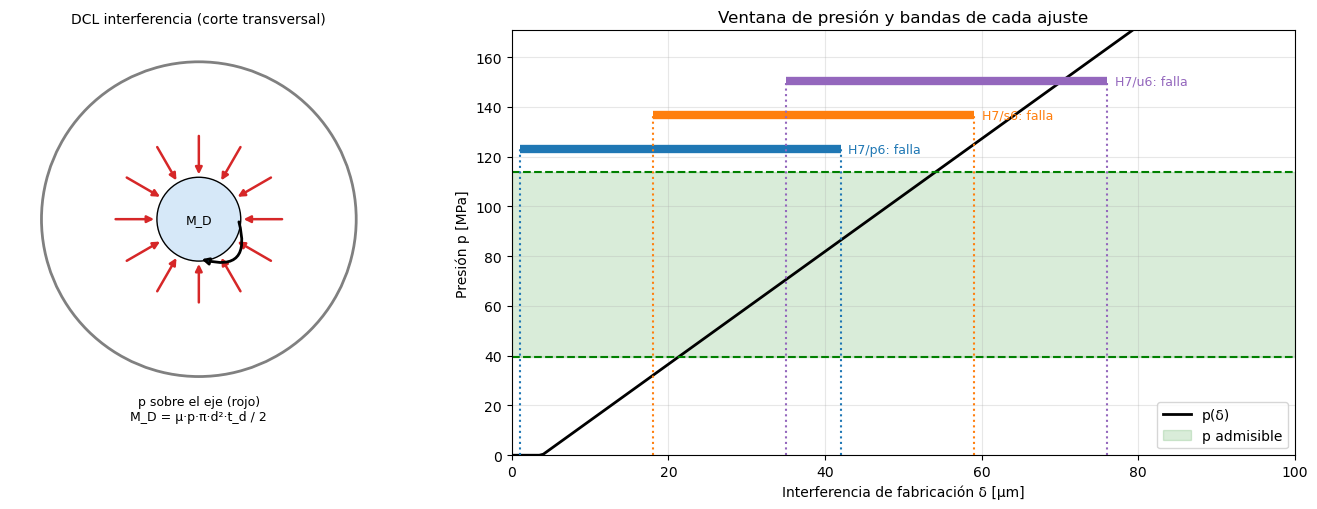

In [21]:
# ===== INTERFERENCIA polea D–eje | unidades: N, mm, MPa, µm =====
mu, t_d, N_0 = UNIONES['interf']['mu'], UNIONES['interf']['t_cubo'], N_f   # [-] ; [mm] ancho del cubo (SUPUESTO) ; [-]  — ver UNIONES
d, d_o = d_eje*1000, d_d*1000            # [mm] eje ; diámetro exterior del cubo (si el cubo es menor que la polea, pon ese valor)
Ra_i = Ra_o = UNIONES['interf']['Ra']      # [µm] rugosidades (supuesto) para Falk
E, M_Dm = E_eje, M_D*1000                # [MPa] ; [N·mm]
p_min = 2*M_Dm/(np.pi*mu*d**2*t_d)                               # [MPa]
k = (d_o**2 + d**2)/(d_o**2 - d**2)                              # [-]
vm_cubo, vm_eje = np.sqrt(k**2 + k + 1), 1.0                     # [-] σ̄/p
p_max = S0_eje/(N_0*max(vm_cubo, vm_eje))                        # [MPa]
Lam = (d_o**2 - d**2)*d**2/d_o**2                                # [mm²]
um_por_MPa = 2*d**3/(E*Lam)*1000                                 # [µm/MPa]  δ = um_por_MPa · p
falk = 1.2*(Ra_i + Ra_o)                                         # [µm] 1,2(μi+μo)·1e-3 mm
d_req_min, d_req_max = p_min*um_por_MPa + falk, p_max*um_por_MPa + falk      # [µm] interferencia de fabricación requerida
print(f'p_min = {p_min:.1f} MPa | p_max = {p_max:.1f} MPa (σ̄/p cubo = {vm_cubo:.2f}) | Λ = {Lam:.0f} mm²')
print(f'δ de fabricación requerida: {d_req_min:.1f} µm  ≤  δ  ≤  {d_req_max:.1f} µm   (incluye Falk = {falk:.1f} µm)\n')

# Ajustes para Ø30–50 mm: (agujero sup, inf, eje sup, inf) en µm. p6: diap. 10-11 ; s6, u6: ISO 286 (no están en las tablas del PPT)
ajustes = {'H7/p6': (25, 0, 42, 26), 'H7/s6': (25, 0, 59, 43), 'H7/u6': (25, 0, 76, 60)}
res = {}
for nom, (Ts_h, Ti_h, Ts_e, Ti_e) in ajustes.items():
    dmax, dmin = Ts_e - Ti_h, Ti_e - Ts_h                         # [µm]  δmáx = (Te)s-(Ta)i ; δmín = (Te)i-(Ta)s
    pmin_f, pmax_f = max(dmin - falk, 0)/um_por_MPa, (dmax - falk)/um_por_MPa     # [MPa]
    res[nom] = (dmin, dmax, pmin_f, pmax_f, pmin_f >= p_min and pmax_f <= p_max)
    print(f'{nom}: δ = {dmin}…{dmax} µm -> p = {pmin_f:.1f}…{pmax_f:.1f} MPa -> {"CUMPLE" if res[nom][4] else "NO cumple"} '
          f'(mín {"ok" if pmin_f >= p_min else "FALLA"}, máx {"ok" if pmax_f <= p_max else "FALLA"})')

fig, ax = plt.subplots(1, 2, figsize=(14, 5.2), gridspec_kw={'width_ratios': [1, 1.5]})
a0 = ax[0]; a0.add_patch(Circle((0,0), 1.0, fc='none', ec='gray', lw=2)); a0.add_patch(Circle((0,0), d/d_o*0.999, fc='#d6e8f8', ec='k'))   # (a) DCL
for ang in np.radians(np.arange(0, 360, 30)):
    r1, r2 = d/d_o, d/d_o + 0.28
    a0.annotate('', xy=(r1*np.cos(ang), r1*np.sin(ang)), xytext=(r2*np.cos(ang), r2*np.sin(ang)), arrowprops=dict(arrowstyle='-|>', color='tab:red', lw=1.8))
a0.annotate('', xy=(0.0, -0.25), xytext=(0.25, 0.0), arrowprops=dict(arrowstyle='-|>', connectionstyle='arc3,rad=-0.9', lw=2))
a0.text(0, 0, 'M_D', ha='center', va='center', fontsize=9); a0.text(0, -1.12, 'p sobre el eje (rojo)\nM_D = μ·p·π·d²·t_d / 2', ha='center', va='top', fontsize=9)
a0.set_aspect('equal'); a0.set_xlim(-1.2, 1.2); a0.set_ylim(-1.5, 1.2); a0.axis('off'); a0.set_title('DCL interferencia (corte transversal)', fontsize=10)
b = ax[1]; dd = np.linspace(0, 100, 200)                          # (b) presión vs interferencia y ajustes
b.plot(dd, np.clip(dd - falk, 0, None)/um_por_MPa, 'k', lw=2, label='p(δ)')
b.axhspan(p_min, p_max, color='green', alpha=.15, label='p admisible'); b.axhline(p_min, c='g', ls='--'); b.axhline(p_max, c='g', ls='--')
for i, ((nom, r), c) in enumerate(zip(res.items(), ['tab:blue', 'tab:orange', 'tab:purple'])):
    yy = p_max*(1.08 + 0.12*i); b.hlines(yy, r[0], r[1], colors=c, lw=6)            # banda δmín…δmáx del ajuste
    for xx in r[:2]: b.plot([xx, xx], [0, yy], c=c, ls=':')
    b.text(r[1] + 1, yy, f'{nom}: {"OK" if r[4] else "falla"}', color=c, va='center', fontsize=9)
b.set_xlabel('Interferencia de fabricación δ [µm]'); b.set_ylabel('Presión p [MPa]'); b.set_xlim(0, 100); b.set_ylim(0, p_max*1.5)
b.legend(loc='lower right'); b.grid(alpha=.3); b.set_title('Ventana de presión y bandas de cada ajuste')
plt.tight_layout(); plt.show()

> ✍️ **REDACTAR · §4.2 Diseño por interferencia en polea D**  _(borrar este recuadro al terminar)_
>
> - **Requisito:** presión mínima para transmitir T_D (μ = ⟦0,1⟧ justificar) y presión máxima admisible (fluencia del cubo con N_0 = `N_f`); intervalo de interferencia de fabricación incluyendo alisado de Falk.
> - **Selección del ajuste ISO 286:** ⟦H7/p6, H7/s6, H7/u6, …⟧ con δ_mín y δ_máx, y presiones resultantes. ⚠ Con los supuestos actuales (cubo de 60 mm, Ø exterior 150 mm) **ningún** ajuste de la celda cumple ambos límites: ⟦decidir: alargar el cubo, ajuste intermedio, calentamiento/enfriamiento, o revisar N_0⟧.
> - Ancho del cubo t_d = ⟦60 mm: justificado con ⟧; diámetro exterior del cubo ⟦150 mm⟧.
> - Figura 5: esquema de la unión (presión p, par T_D, fuerza de roce) ⟦dibujar⟧.

### 4.3 Diseño por pasador en polea F

Corte y compresión del pasador
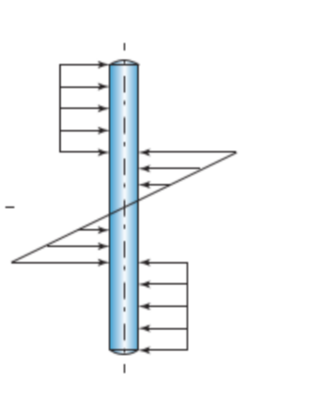

**Modelo de carga de la diap. 16 (EM4)**: cubo uniforme, eje triangular. Resultantes en sus centroides (medidos desde el eje) y equilibrio de pares:
$$S=\frac{D_N-D}{2},\quad a=\frac{D}{2}+\frac{S}{2},\quad b=\frac{D}{3},\qquad 2F_P\,b=T\Rightarrow F_P=\frac{3T}{2D},\qquad 2F_D\,a=T\Rightarrow F_D=\frac{T}{D+S}$$
$$V_{max}=\max(F_D,\ F_P-F_D),\qquad M_{max}=F_D(a-b)\ \ (\text{en } y=\pm b),\qquad M(0)=0$$
$$\tau=\frac{4V_{max}}{\pi d_p^2}\le\frac{S_0/\sqrt3}{N},\quad \sigma_f=\frac{32M_{max}}{\pi d_p^3},\quad \sigma_{ap,cubo}=\frac{F_D}{S\,d_p},\quad \sigma_{ap,eje}=\frac{6T}{D^2d_p},\quad \sigma_{eq}=\sqrt{\sigma_f^2+3\tau^2}\le\frac{S_0}{N}$$
Comparación: modelo clásico $T=F\,D$ con $V=F=T/D$ y $M=0$.

| Variable | Definición | Unidad |
|---|---|---|
| $T$ | Torque en F ($=M_F\cdot1000$) | $[N\cdot mm]$ |
| $D,\ D_N,\ d_p$ | Diámetro del eje, del cubo y del pasador | $[mm]$ |
| $F_P,\ F_D,\ V$ | Resultantes (eje, cubo) y cortante | $[N]$ |
| $a,\ b,\ S$ | Posiciones de las resultantes y tramo de cubo | $[mm]$ |
| $M$ | Momento flector en el pasador | $[N\cdot mm]$ |
| $\tau,\ \sigma$ | Esfuerzos | $[MPa]$ |

F_P = 22262 N | F_D = 9894 N | V_max = 12368 N | M_max = 164.9 N·m | (clásico: F = V = 14841 N, M = 0)
chequeo de pares: 2·F_P·b = 593648 = 2·F_D·a = 593648 = T = 593648 N·mm
d_p = 22.0 mm -> Corte N=6.03 | Flexión N=2.16 | Aplast. cubo N=15.12 | Aplast. eje N=3.36 | Von Mises N=2.03
N mínimo = 2.03 (CUMPLE con N = 1.6) | d_p mínimo = 20.3 mm = 0.51·D


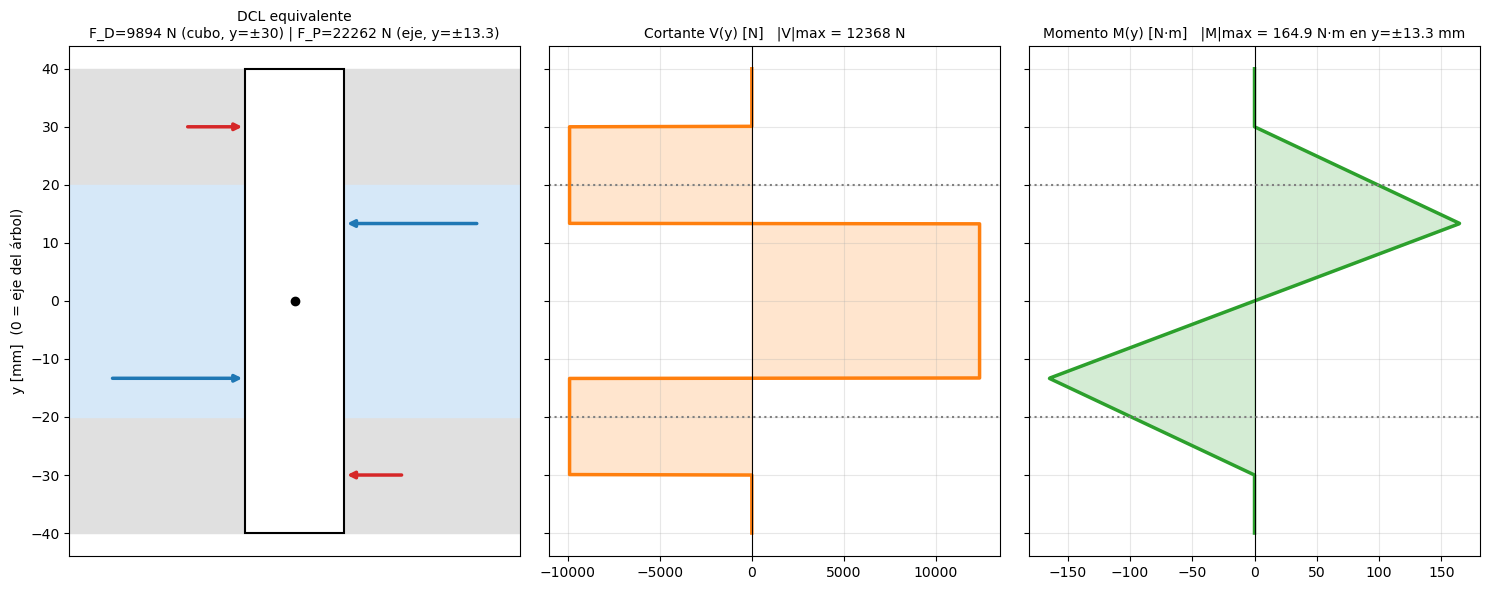

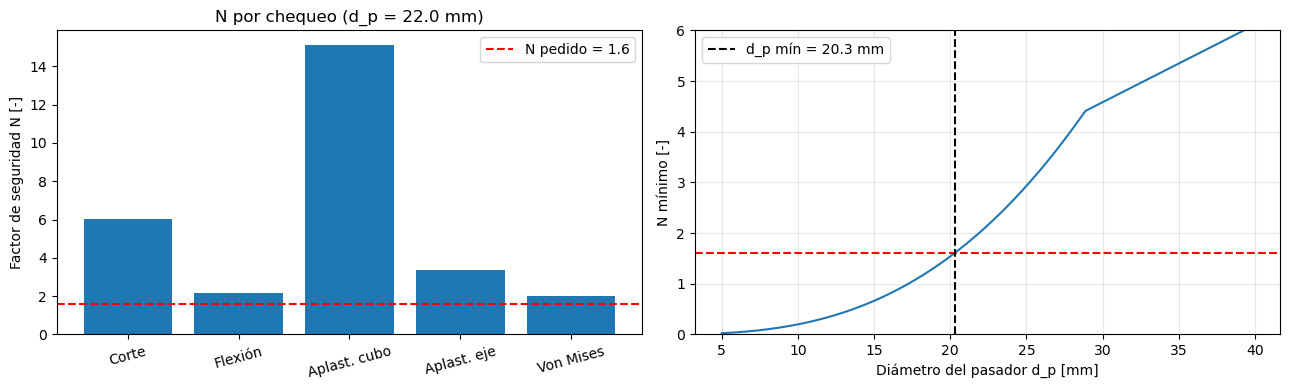

In [22]:
# ===== PASADOR polea F–eje | unidades: N, mm, MPa =====
T_Fmm, D, D_N, d_p = M_F*1000, d_eje*1000, UNIONES['pasador']['D_N'], UNIONES['pasador']['d_p']   # [N·mm] ; [mm] eje ; [mm] cubo ; [mm] pasador — ver UNIONES
S_c = (D_N - D)/2; a = D/2 + S_c/2; b = D/3                # [mm]
F_P, F_D, F_cl = 3*T_Fmm/(2*D), T_Fmm/(D + S_c), T_Fmm/D         # [N] Método 2 (eje, cubo) y Método 1 clásico
V_max, M_max = max(F_D, F_P - F_D), F_D*(a - b)            # [N] ; [N·mm]
def N_pas(dp):                                             # factores de seguridad de cada chequeo [-]
    tau, sf = 4*V_max/(np.pi*dp**2), 32*M_max/(np.pi*dp**3)
    return {'Corte': S0_eje/np.sqrt(3)/tau, 'Flexión': S0_eje/sf, 'Aplast. cubo': S0_eje/(F_D/(S_c*dp)),
            'Aplast. eje': S0_eje/(6*T_Fmm/(D**2*dp)), 'Von Mises': S0_eje/np.hypot(sf, np.sqrt(3)*tau)}
Ns = N_pas(d_p); dps = np.arange(5, 40, 0.1)
dp_min = next((x for x in dps if min(N_pas(x).values()) >= N_f), np.nan)                 # [mm]
print(f'F_P = {F_P:.0f} N | F_D = {F_D:.0f} N | V_max = {V_max:.0f} N | M_max = {M_max/1000:.1f} N·m | (clásico: F = V = {F_cl:.0f} N, M = 0)')
print(f'chequeo de pares: 2·F_P·b = {2*F_P*b:.0f} = 2·F_D·a = {2*F_D*a:.0f} = T = {T_Fmm:.0f} N·mm')
print(f'd_p = {d_p} mm -> ' + ' | '.join(f'{k} N={v:.2f}' for k, v in Ns.items()) + f'\nN mínimo = {min(Ns.values()):.2f} ({"CUMPLE" if min(Ns.values()) >= N_f else "NO cumple"} con N = {N_f}) | d_p mínimo = {dp_min:.1f} mm = {dp_min/D:.2f}·D')

y = np.linspace(-D_N/2, D_N/2, 1001); car = [(-a, -F_D), (-b, F_P), (b, -F_P), (a, F_D)]      # fuerzas puntuales (y, f)
V = sum(f*(y > yi) for yi, f in car); M = sum(f*(y - yi)*(y > yi) for yi, f in car)/1000      # [N] ; [N·m]
fig, ax = plt.subplots(1, 3, figsize=(15, 6), sharey=True)
a0 = ax[0]; a0.axhspan(D/2, D_N/2, color='0.88'); a0.axhspan(-D_N/2, -D/2, color='0.88'); a0.axhspan(-D/2, D/2, color='#d6e8f8')
a0.add_patch(Rectangle((-d_p/2, -D_N/2), d_p, D_N, fc='white', ec='k', lw=1.5, zorder=3)); a0.plot(0, 0, 'ko', zorder=5)
for yi, f in car:                                           # f>0 -> hacia +x (azul = eje, rojo = cubo)
    x0, x1 = (-d_p/2 - 30*abs(f)/F_P, -d_p/2) if f > 0 else (d_p/2 + 30*abs(f)/F_P, d_p/2)
    a0.annotate('', xy=(x1, yi), xytext=(x0, yi), zorder=6, arrowprops=dict(arrowstyle='-|>', lw=2.5, color='tab:red' if abs(yi) == a else 'tab:blue'))
a0.set_xlim(-50, 50); a0.set_xticks([]); a0.set_ylabel('y [mm]  (0 = eje del árbol)')
a0.set_title(f'DCL equivalente\nF_D={F_D:.0f} N (cubo, y=±{a:.0f}) | F_P={F_P:.0f} N (eje, y=±{b:.1f})', fontsize=10)
ax[1].plot(V, y, c='tab:orange', lw=2.5); ax[1].fill_betweenx(y, V, alpha=.2, color='tab:orange'); ax[1].set_title(f'Cortante V(y) [N]   |V|max = {V_max:.0f} N', fontsize=10)
ax[2].plot(M, y, c='tab:green', lw=2.5); ax[2].fill_betweenx(y, M, alpha=.2, color='tab:green'); ax[2].set_title(f'Momento M(y) [N·m]   |M|max = {M_max/1000:.1f} N·m en y=±{b:.1f} mm', fontsize=10)
for k in (1, 2):
    ax[k].axvline(0, c='k', lw=.8); ax[k].grid(alpha=.3)
    for yy in (D/2, -D/2): ax[k].axhline(yy, c='gray', ls=':')
plt.tight_layout(); plt.show()
fig, ax2 = plt.subplots(1, 2, figsize=(13, 4))                # N por chequeo y selección de d_p
ax2[0].bar(list(Ns), list(Ns.values()), color='tab:blue'); ax2[0].axhline(N_f, c='r', ls='--', label=f'N pedido = {N_f}')
ax2[0].set_ylabel('Factor de seguridad N [-]'); ax2[0].set_title(f'N por chequeo (d_p = {d_p} mm)'); ax2[0].legend(); ax2[0].tick_params(axis='x', rotation=15)
ax2[1].plot(dps, [min(N_pas(x).values()) for x in dps]); ax2[1].axhline(N_f, c='r', ls='--'); ax2[1].axvline(dp_min, c='k', ls='--', label=f'd_p mín = {dp_min:.1f} mm')
ax2[1].set_ylim(0, 6); ax2[1].set_xlabel('Diámetro del pasador d_p [mm]'); ax2[1].set_ylabel('N mínimo [-]'); ax2[1].legend(); ax2[1].grid(alpha=.3)
plt.tight_layout(); plt.show()

F = T/D = 14841 N -> V = 14841 N en cada plano (y = ±20 mm), M = 0
d_p = 22.0 mm -> Corte N=5.03 | Aplast. cubo N=10.08 | Aplast. eje N=10.08 | Von Mises N=5.03 | Flexión: M = 0
N mínimo = 5.03 | d_p mínimo = 12.5 mm = 0.31·D   (Método 2: 20.3 mm)


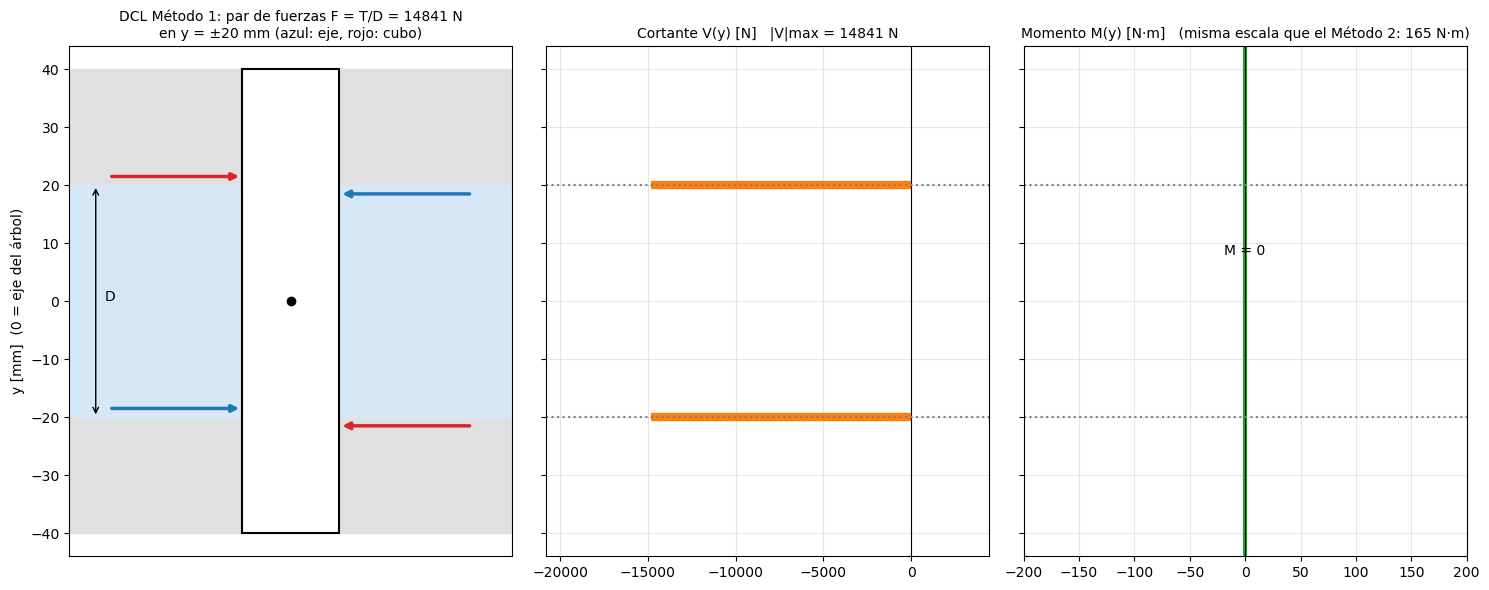

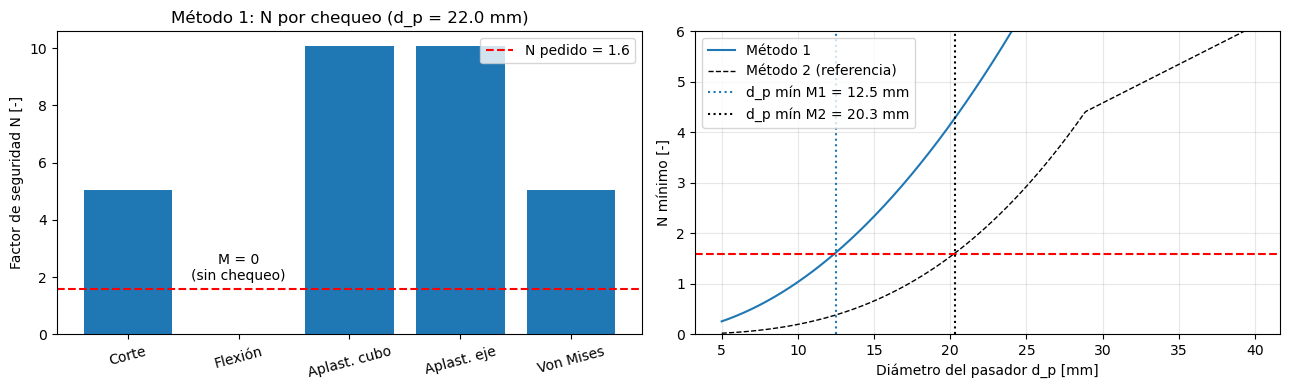

In [23]:
# ===== PASADOR · MÉTODO 1 (T = F·D): fuerzas justo en el cambio eje→cubo | unidades: N, mm, MPa =====
V1p = F_cl                                                   # [N] cortante en cada plano de corte (y = ±D/2) ; M = 0 (no hay brazo)
def N_pas1(dp):                                              # factores de seguridad [-]; sin flexión no hay chequeo de flexión
    tau = 4*V1p/(np.pi*dp**2)                                # [MPa]
    return {'Corte': S0_eje/np.sqrt(3)/tau, 'Flexión': np.nan, 'Aplast. cubo': S0_eje/(F_cl/(S_c*dp)),
            'Aplast. eje': S0_eje/(F_cl/((D/2)*dp)), 'Von Mises': S0_eje/(np.sqrt(3)*tau)}
nmin = lambda f, x: np.nanmin(list(f(x).values()))
Ns1 = N_pas1(d_p); dp_min1 = next((x for x in dps if nmin(N_pas1, x) >= N_f), np.nan)           # [mm]
print(f'F = T/D = {F_cl:.0f} N -> V = {V1p:.0f} N en cada plano (y = ±{D/2:.0f} mm), M = 0')
print(f'd_p = {d_p} mm -> ' + ' | '.join(f'{k} N={v:.2f}' for k, v in Ns1.items() if not np.isnan(v)) + ' | Flexión: M = 0')
print(f'N mínimo = {min(v for v in Ns1.values() if not np.isnan(v)):.2f} | d_p mínimo = {dp_min1:.1f} mm = {dp_min1/D:.2f}·D   (Método 2: {dp_min:.1f} mm)')

e = 1.5                                                      # [mm] separación SOLO para dibujar (en el modelo, eje y cubo coinciden en y = ±D/2)
fig, ax = plt.subplots(1, 3, figsize=(15, 6), sharey=True); a0 = ax[0]
a0.axhspan(D/2, D_N/2, color='0.88'); a0.axhspan(-D_N/2, -D/2, color='0.88'); a0.axhspan(-D/2, D/2, color='#d6e8f8')
a0.add_patch(Rectangle((-d_p/2, -D_N/2), d_p, D_N, fc='white', ec='k', lw=1.5, zorder=3)); a0.plot(0, 0, 'ko', zorder=5)
for s in (1, -1):                                            # azul = eje, rojo = cubo
    for yy, f, c in [(s*(D/2 - e), -s*F_cl, 'tab:blue'), (s*(D/2 + e), s*F_cl, 'tab:red')]:
        x0, x1 = (-d_p/2 - 30, -d_p/2) if f > 0 else (d_p/2 + 30, d_p/2)
        a0.annotate('', xy=(x1, yy), xytext=(x0, yy), zorder=6, arrowprops=dict(arrowstyle='-|>', lw=2.5, color=c))
a0.annotate('', xy=(-44, D/2), xytext=(-44, -D/2), arrowprops=dict(arrowstyle='<->')); a0.text(-42, 0, 'D')
a0.set_xlim(-50, 50); a0.set_xticks([]); a0.set_ylim(-D_N/2 - 4, D_N/2 + 4); a0.set_ylabel('y [mm]  (0 = eje del árbol)')
a0.set_title(f'DCL Método 1: par de fuerzas F = T/D = {F_cl:.0f} N\nen y = ±{D/2:.0f} mm (azul: eje, rojo: cubo)', fontsize=10)
ax[1].hlines([D/2, -D/2], 0, -V1p, lw=6, color='tab:orange'); ax[1].set_xlim(-1.4*V1p, 0.3*V1p)
ax[1].set_title(f'Cortante V(y) [N]   |V|max = {V1p:.0f} N', fontsize=10)
ax[2].axvline(0, c='tab:green', lw=3); ax[2].set_xlim(-200, 200); ax[2].text(0, 8, 'M = 0', ha='center')
ax[2].set_title(f'Momento M(y) [N·m]   (misma escala que el Método 2: {M_max/1000:.0f} N·m)', fontsize=10)
for k in (1, 2):
    ax[k].axvline(0, c='k', lw=.8); ax[k].grid(alpha=.3)
    for yy in (D/2, -D/2): ax[k].axhline(yy, c='gray', ls=':')
plt.tight_layout(); plt.show()

fig, ax2 = plt.subplots(1, 2, figsize=(13, 4))               # N por chequeo y selección de d_p
ax2[0].bar(list(Ns1), list(Ns1.values()), color='tab:blue'); ax2[0].axhline(N_f, c='r', ls='--', label=f'N pedido = {N_f}')
ax2[0].text(1, N_f + .3, 'M = 0\n(sin chequeo)', ha='center'); ax2[0].set_ylabel('Factor de seguridad N [-]')
ax2[0].set_title(f'Método 1: N por chequeo (d_p = {d_p} mm)'); ax2[0].legend(); ax2[0].tick_params(axis='x', rotation=15)
ax2[1].plot(dps, [nmin(N_pas1, x) for x in dps], label='Método 1'); ax2[1].plot(dps, [nmin(N_pas, x) for x in dps], 'k--', lw=1, label='Método 2 (referencia)')
ax2[1].axhline(N_f, c='r', ls='--'); ax2[1].axvline(dp_min1, c='tab:blue', ls=':', label=f'd_p mín M1 = {dp_min1:.1f} mm'); ax2[1].axvline(dp_min, c='k', ls=':', label=f'd_p mín M2 = {dp_min:.1f} mm')
ax2[1].set_ylim(0, 6); ax2[1].set_xlabel('Diámetro del pasador d_p [mm]'); ax2[1].set_ylabel('N mínimo [-]'); ax2[1].legend(); ax2[1].grid(alpha=.3)
plt.tight_layout(); plt.show()

> ✍️ **REDACTAR · §4.3 Diseño por pasador en polea F**  _(borrar este recuadro al terminar)_
>
> - **Tipo:** pasador cilíndrico ⟦liso, doble corte⟧ y **material** ⟦nombre, S_0⟧ (en el informe de referencia, acero estructural Grado 350: S_0 = 350 MPa).
> - **Modelo de carga:** Método 1 (clásico, T = F·D, sin flexión) vs Método 2 (EM4 diap. 16: cubo uniforme / eje triangular, con flexión). Se adopta ⟦Método 2⟧ por ⟦ser más conservador: incluye M_máx⟧.
> - **Resultados:** F_P, F_D, V_máx, M_máx; N a corte, flexión, aplastamiento (cubo y eje) y Von Mises; d_p mínimo para N = `N_f`; d_p adoptado ⟦22 mm / normalizado⟧ y largo total ⟦= Ø cubo⟧.
> - **Fatiga del eje en el agujero del pasador:** K_t de agujero transversal ⟦figura⟧ → `FAT["K_ff"]` (§5).

### 4.4 Unión apernada de las planchas cuadradas _(Tabla 1: "Apernada"; no figura como sección en la pauta)_

> ✍️ **REDACTAR · §4.4 Planchas cuadradas 250×250×10 sobre plancha de 20 mm**  _(borrar este recuadro al terminar)_
>
> - ⟦Confirmar con el profesor si esta unión se evalúa en el informe; el objetivo 5 pide su plano de detalle.⟧
> - Cargas por soporte: usar R1 (x,y) y R2 (x,y,z) de `DCL["eje"]` (la plancha 2 recibe la mayor: |R2x| ≈ 19,9 kN).
> - Selección de perno (clase, Ø, nº), precarga, verificación a corte/tracción y aplastamiento ⟦RELLENAR⟧.

## 5. Verificación del eje: fatiga y factor de seguridad a la fluencia

,Sección,s [m],M_res [N·m],|T| [N·m],σ_max [MPa],τ_max [MPa],N fatiga,N fluencia
0,C,0.30,3302.0,1187.3,525.6,94.5,0.39,0.62
1,D,1.05,4191.0,1187.3,667.0,94.5,0.31,0.50
2,Ap.2,1.45,3137.0,593.6,499.3,47.2,0.42,0.67
3,F,1.65,16.0,593.6,2.5,47.2,3.97,4.15


Crítica: s = 1.05 m | N_fatiga = 0.31 (requisito 1.6) | N_fluencia mín = 0.49 | Ø necesario en esa sección (K_f = 1) ≈ 70.5 mm


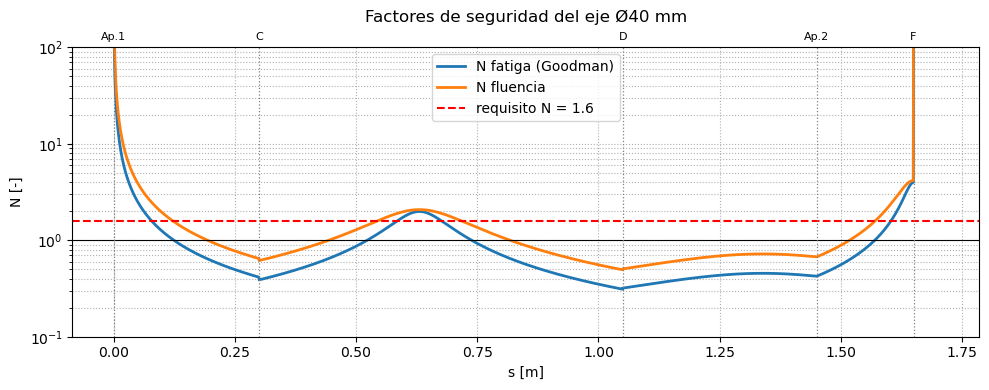

In [24]:
# =====================================================================
# 5. VERIFICACIÓN DEL EJE: FATIGA (Goodman + Von Mises, EM1 diap. 27–28) Y FLUENCIA
# =====================================================================
CICLO = {'flexion': 'invertida',   # carga fija en el espacio + eje que gira  ->  σ_a = σ_max , σ_m = 0
         'torsion': 'pulsante'}    # la potencia alterna 0 ↔ P_max (pauta, Metodología)  ->  τ_a = τ_m = τ_max/2 ;  'constante': τ_a = 0 , τ_m = τ_max
def verif_eje(d_m, M, T_, Kff=None, Kft=None):
    """N a fatiga y a fluencia (vectorizado). d_m [m] ; M, T_ [N·m]."""
    Kff = FAT['K_ff'] if Kff is None else Kff; Kft = FAT['K_ft'] if Kft is None else Kft
    dm = np.asarray(d_m, float)*1000                                   # [mm]
    sb  = 32*np.abs(M)*1e3/(np.pi*dm**3)                               # [MPa] σ_max por flexión
    tmx = 16*np.abs(T_)*1e3/(np.pi*dm**3)                              # [MPa] τ_max por torsión
    ta, tm = (tmx/2, tmx/2) if CICLO['torsion'] == 'pulsante' else (0*tmx, tmx)
    sa_eq = np.sqrt((Kff*sb)**2 + 3*(Kft*ta)**2)                       # σ_a' (K_f solo en la parte alterna)
    sm_eq = np.sqrt(3)*tm                                              # σ_m' (σ_m = 0)
    Sf = Sf_eje_fn(np.asarray(d_m, float))[0]
    with np.errstate(divide='ignore'):                                  # secciones sin carga -> N = ∞
        Nfat = 1/(sa_eq/Sf + sm_eq/Sr_eje)                             # Goodman
        Nflu = S0_eje/np.sqrt(sb**2 + 3*tmx**2)                        # fluencia, valores máximos simultáneos
    return Nfat, Nflu, sb, tmx
s_ax = DIAG['s']                                                      # [m] (copia local: otras celdas reutilizan el nombre 's')
Nfat_s, Nflu_s, sb_s, tmx_s = verif_eje(d_eje, DIAG['M_res'], DIAG['T'])

filas = []
for nom_, si in [('C', pos['C']), ('D', pos['D']), ('Ap.2', pos['Ap2']), ('F', pos['F'])]:
    idx = [en(si, -1), en(si, +1)]                                     # ambos lados de la sección (T salta)
    j = idx[int(np.argmin(Nfat_s[idx]))]
    filas.append((nom_, si, DIAG['M_res'][j], abs(DIAG['T'][j]), sb_s[j], tmx_s[j], Nfat_s[j], Nflu_s[j]))
TABLA_FATIGA = pd.DataFrame(filas, columns=['Sección', 's [m]', 'M_res [N·m]', '|T| [N·m]', 'σ_max [MPa]', 'τ_max [MPa]', 'N fatiga', 'N fluencia']).round({'s [m]': 2, 'M_res [N·m]': 0, '|T| [N·m]': 1, 'σ_max [MPa]': 1, 'τ_max [MPa]': 1, 'N fatiga': 2, 'N fluencia': 2})
display(TABLA_FATIGA)
jc = int(np.argmin(Nfat_s))
dgrid = np.arange(d_eje*1000, 150, 0.5)/1000                           # [m]
Nf_g, Ny_g, *_ = verif_eje(dgrid, DIAG['M_res'][jc], DIAG['T'][jc])
d_req = next((x*1000 for x, n in zip(dgrid, Nf_g) if n >= N_f), np.nan)
print(f"Crítica: s = {s_ax[jc]:.2f} m | N_fatiga = {Nfat_s[jc]:.2f} (requisito {N_f}) | N_fluencia mín = {Nflu_s.min():.2f} | Ø necesario en esa sección (K_f = 1) ≈ {d_req:.1f} mm")

fig, a = plt.subplots(figsize=(10, 4)); a.semilogy(s_ax, np.clip(Nfat_s, 1e-3, 1e3), label='N fatiga (Goodman)', lw=2); a.semilogy(s_ax, np.clip(Nflu_s, 1e-3, 1e3), label='N fluencia', lw=2)
a.axhline(N_f, c='r', ls='--', label=f'requisito N = {N_f}'); a.axhline(1, c='k', lw=.8); a.set_ylim(.1, 100); a.grid(True, which='both', ls=':'); _marcas(a); a.legend(); a.set_ylabel('N [-]'); a.set_xlabel('s [m]'); a.set_title(f'Factores de seguridad del eje Ø{d_eje*1000:.0f} mm', pad=18); plt.tight_layout(); plt.show()

> ✍️ **REDACTAR · §5 Fatiga y fluencia del eje**  _(borrar este recuadro al terminar)_
>
> - **Modelo de carga (traducción de las fuerzas de los engranes a carga dinámica):** el eje gira bajo cargas de dirección fija → flexión **totalmente invertida** (σ_a = σ_máx, σ_m = 0). El "0 → F" de la literatura corresponde a la raíz del diente, no al eje. La potencia alterna entre 0 y P_máx (arranque–parada, pauta) → torsión **pulsante** (τ_a = τ_m = τ_máx/2). Editar `CICLO` si el profesor pide otro criterio.
> - **Criterio:** Von Mises con K_f solo en la parte alterna + Goodman, N_f ≥ `N_f`; límite de fatiga corregido S_f (C_t, C_s calculados; C_i ⟦decidir confiabilidad⟧).
> - **Resultados con Ø40 mm:** ⟦N_fatiga y N_fluencia por sección (tabla); sección crítica D⟧. El requisito de la Tabla 1 (fatiga) **no se cumple** con Ø40 mm uniforme: ⟦decidir: eje escalonado (el plano "sin calcular diámetros" lo permite), cambio de material/tratamiento, o revisar cargas con el profesor⟧.
> - **Objetivo 6:** el N a fluencia es el resultado de la columna "N fluencia" en la sección crítica, calculado aparte del requisito de fatiga.

## 6. Discusión y conclusiones

> ✍️ **REDACTAR · Discusión**  _(borrar este recuadro al terminar)_
>
> - Efecto de los supuestos: reparto de potencia D/F, criterio de β, ancho del cubo, material de la chaveta/pasador, largo del eje (`DATOS`, `UNIONES`).
> - Comparación entre métodos del pasador (1 vs 2) y qué ve cada uno.
> - Por qué el ajuste por interferencia estándar no cumple y qué se hizo ⟦RELLENAR⟧.
> - Resultado de fatiga/fluencia del eje y su implicancia en el plano de detalle (escalones, radios, chaflanes).
> - Limitaciones: engranes rectos sin carga axial, correas en el plano XY, sin factor dinámico de engranes (v ≈ 0,38 m/s ≈ 1), apoyos como rótulas.

> ✍️ **REDACTAR · Conclusiones (20 % de la nota)**  _(borrar este recuadro al terminar)_
>
> - Una conclusión por objetivo específico, con el número que lo respalda: ⟦DCL: R1, R2⟧ · ⟦M_máx y T_máx⟧ · ⟦chaveta: dimensiones y N⟧ · ⟦interferencia: ajuste y p⟧ · ⟦pasador: d_p y N⟧ · ⟦N_fluencia del diseño⟧.
> - Conclusión general: ¿el diseño cumple N_fatiga = `N_f`? ⟦sí/no y qué cambia⟧.
> - Anexos: ⟦plano del eje · plano de planchas⟧ y referencias (APA/IEEE).